# CIS 490 Cyber Defense Project Notebook — Final Project Setup

## Project Goal
Build a machine learning workflow that recommends cyber defense countermeasures from CVE vulnerability data.

This notebook uses the instructor-provided **unified CVE dataset**, which already connects:

**CVE → CWE → CAPEC → MITRE ATT&CK Technique → MITRE ATT&CK Mitigation**

## Main ML tasks in this notebook
1. **CWE classification:** predict the weakness category from the CVE description.
2. **Mitigation recommendation:** predict/rank likely defensive mitigations from the CVE description.

## Recommended dataset
Use one of the instructor-provided files:

- `cve_unified_100k.csv` Train
- `cve_unified_100k_2025-2026.csv` Test




## 1: Upload or Mount Files in Colab

In this section, the dataset required for the project is made available within the Google Colab environment.

Because Colab runs in a cloud-based environment, local files are not directly accessible by default. Therefore, files must either be uploaded manually or accessed by mounting Google Drive.

This step ensures that the notebook can locate and load the necessary datasets, such as the unified CVE and CVSS data, for further processing and analysis.

Proper file configuration is essential because all subsequent steps—including data cleaning, feature engineering, model training, and evaluation—depend on successfully loading the dataset into the environment.

In [ ]:
import pandas as pd
import os

# Files uploaded directly into Colab usually appear in /content
UPLOAD_DIR = "/content"

train_filename = "cve_unified_100k.csv"
test_filename = "cve_unified_100k_2025-2026.csv"

train_path = os.path.join(UPLOAD_DIR, train_filename)
test_path = os.path.join(UPLOAD_DIR, test_filename)

# Debug + error handling
missing = []

if not os.path.exists(train_path):
    missing.append(train_filename)

if not os.path.exists(test_path):
    missing.append(test_filename)

if missing:
    print("Missing dataset file(s):", missing)
    print("\nFiles currently uploaded to /content:\n")
    for file in os.listdir(UPLOAD_DIR):
        print(file)

    raise FileNotFoundError(
        "\nUpload BOTH files directly into the notebook runtime:\n"
        "- cve_unified_100k.csv\n"
        "- cve_unified_100k_2025-2026.csv"
    )

# Load datasets
print("Training file found:", train_path)
print("Testing file found:", test_path)

train_df = pd.read_csv(train_path, on_bad_lines='skip')
test_df = pd.read_csv(test_path, on_bad_lines='skip')

print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training file found: /content/cve_unified_100k.csv
Testing file found: /content/cve_unified_100k_2025-2026.csv

Training dataset shape: (100000, 32)
Testing dataset shape: (67856, 32)


## 2: Imports and Settings

In this section, the necessary Python libraries and configurations are initialized to support data processing, visualization, and machine learning tasks.

Key libraries such as pandas and numpy are used for data manipulation, while matplotlib is used for visualization. Scikit-learn modules are imported to build and evaluate machine learning models, including tools for feature extraction (TF-IDF), model training, and performance metrics.

Additionally, global settings are configured to ensure consistent results and improved readability. For example, a fixed random seed is set to make model results reproducible, and display options are adjusted to allow for easier inspection of data within the notebook.

This step is important because it establishes the foundational tools and environment needed for all subsequent stages of the project, including data preprocessing, model development, and evaluation.

In [ ]:
import ast
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    hamming_loss
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

## 3: File Configuration

In this section, file paths and dataset locations are defined to ensure that the notebook can correctly locate and access the required data files.

This includes specifying directories, file names, and potential file formats (such as CSV or Parquet). Helper functions may also be used to search for available files or select the correct dataset automatically.

This step is important because it provides flexibility and portability. By centralizing file paths and configuration settings, the notebook can be easily adapted to different environments or datasets without modifying the core code.

Proper file configuration ensures that the data loading process is reliable and that subsequent steps—such as data cleaning, feature engineering, and model training—can proceed without errors.

In [ ]:
from pathlib import Path

# Colab uploaded files are stored in /content
DATA_DIR = Path("/content")

DATASET_CANDIDATES = [
    "cve_unified_100k_2025-2026.csv",
    "cve_unified_100k.csv"
]

print("Looking for dataset files in:", DATA_DIR.resolve())

for name in DATASET_CANDIDATES:
    file_path = DATA_DIR / name

    if file_path.exists():
        print(f"✅ {name} FOUND")
    else:
        print(f"❌ {name} not found")

print("\n📁 Current files in /content:")
for file in DATA_DIR.iterdir():
    print(file.name)

Looking for dataset files in: /content
✅ cve_unified_100k_2025-2026.csv FOUND
✅ cve_unified_100k.csv FOUND

📁 Current files in /content:
.config
.ipynb_checkpoints
cve_unified_100k.csv
cve_unified_100k_2025-2026.csv
sample_data


## 4: Helper Functions

In this section, reusable helper functions are defined to simplify and organize the workflow of the project.

These functions perform common tasks such as loading datasets, processing text, calculating evaluation metrics (e.g., Top-K hit rates), and formatting model outputs. By encapsulating these operations into functions, the code becomes more modular, readable, and easier to maintain.

Using helper functions also reduces redundancy, as the same logic can be applied consistently across different parts of the notebook without rewriting code.

This step is important because it improves the structure and clarity of the project, making it easier to debug, extend, and understand the overall machine learning pipeline.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import ast


def find_dataset_files(data_dir):
    """Find the required CSV train/test datasets."""
    data_dir = Path(data_dir)

    train_path = data_dir / "cve_unified_100k.csv"
    test_path = data_dir / "cve_unified_100k_2025-2026.csv"

    if not train_path.exists():
        raise FileNotFoundError(f"Training file not found: {train_path}")

    if not test_path.exists():
        raise FileNotFoundError(f"Test file not found: {test_path}")

    return train_path, test_path


def load_csv_dataset(path):
    """Load a CSV dataset."""
    path = Path(path)
    print(f"Loading dataset: {path}")
    return pd.read_csv(path)


def parse_list_cell(value):
    """Convert list-like strings from CSV into Python lists."""
    if isinstance(value, list):
        return value

    if value is None or (isinstance(value, float) and pd.isna(value)):
        return []

    text = str(value).strip()

    if text in {"", "nan", "None", "[]"}:
        return []

    try:
        parsed = ast.literal_eval(text)

        if isinstance(parsed, (list, tuple)):
            return [str(x) for x in parsed if pd.notna(x)]

        if isinstance(parsed, str):
            return [parsed]

    except Exception:
        pass

    return [part.strip() for part in text.split(",") if part.strip()]


def make_text(value):
    """Convert missing values to empty strings and clean text."""
    if pd.isna(value):
        return ""

    return str(value).strip()


def top_k_hit_rate(probabilities, y_true, k=3):
    """
    Multi-label Top-K hit rate.
    A row counts as correct if at least one true label appears
    in the model's top K predicted labels.
    """
    if probabilities.shape[0] == 0:
        return np.nan

    top_k_indices = np.argsort(probabilities, axis=1)[:, -k:]
    hits = 0

    for i in range(y_true.shape[0]):
        true_indices = set(np.where(y_true[i] == 1)[0])
        predicted_indices = set(top_k_indices[i])

        if true_indices.intersection(predicted_indices):
            hits += 1

    return hits / y_true.shape[0]


def show_top_mitigations(probabilities, label_names, row_index, k=5):
    """Show the top K predicted mitigation labels for one row."""
    top_indices = np.argsort(probabilities[row_index])[-k:][::-1]

    return pd.DataFrame({
        "rank": range(1, k + 1),
        "mitigation_id": [label_names[i] for i in top_indices],
        "score": probabilities[row_index, top_indices]
    })

## 5: Load the Unified CVE Dataset

In this section, the unified CVE dataset is loaded into the notebook as a structured DataFrame for analysis and modeling.

The dataset combines information from multiple sources, including CVE identifiers, vulnerability descriptions, CVSS scores, and associated mitigation or attack data. By consolidating this information into a single dataset, it provides a comprehensive view of each vulnerability.

Loading the dataset involves reading the file (e.g., CSV or Parquet format) and verifying its structure, including the number of rows, columns, and sample records. This ensures that the data has been imported correctly and is ready for further processing.

This step is critical because it serves as the foundation for the entire project. All subsequent steps—such as data cleaning, feature engineering, model training, and evaluation—depend on the successful loading and integrity of this dataset.

In [ ]:
train_path, test_path = find_dataset_files(DATA_DIR)

train_df = load_csv_dataset(train_path)
test_df = load_csv_dataset(test_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

print("\nTrain Columns:")
print(train_df.columns.tolist())

Loading dataset: /content/cve_unified_100k.csv
Loading dataset: /content/cve_unified_100k_2025-2026.csv
Train shape: (100000, 32)
Test shape: (67856, 32)


,cve_id,description,cwe_ids,cwe_id,cvss_score,cvss_severity,cvss_vector,cvss_version,exploitability_score,impact_score,cvss_av,cvss_ac,cvss_pr,cvss_ui,cvss_scope,cvss_c,cvss_i,cvss_a,is_kev,has_patch,has_exploit,published,last_modified,vuln_status,vendors,products,capec_ids,attack_ids,mitigation_ids,attack_names,mitigation_names,attack_source
0,CVE-2017-18006,"netpub/server.np in Extensis Portfolio NetPublish has XSS in the quickfind parameter, aka Open Bug Bounty ID OBB-290...",['CWE-79'],CWE-79,6.1,MEDIUM,CVSS:3.0/AV:N/AC:L/PR:N/UI:R/S:C/C:L/I:L/A:N,3.0,2.8,2.7,N,L,N,R,C,L,L,N,False,False,False,2018-01-01 00:29:00.213000+00:00,2025-04-20T01:37:25.860,Deferred,['extensis'],['extensis portfolio_netpublish'],"['CAPEC-209', 'CAPEC-588', 'CAPEC-591', 'CAPEC-592', 'CAPEC-63', 'CAPEC-85']","['T1055', 'T1059.007', 'T1189', 'T1204.001', 'T1557']","['M1026', 'M1040', 'M1038', 'M1042', 'M1021', 'M1050', 'M1051', 'M1048', 'M1017', 'M1031', 'M1037', 'M1041', 'M1035'...","['Process Injection', 'JavaScript', 'Drive-by Compromise', 'Malicious Link', 'Adversary-in-the-Middle']","['Privileged Account Management', 'Behavior Prevention on Endpoint', 'Execution Prevention', 'Disable or Remove Feat...",bridge
1,CVE-2018-3810,Authentication Bypass vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows ...,['CWE-287'],CWE-287,9.8,CRITICAL,CVSS:3.0/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,3.0,3.9,5.9,N,L,N,N,U,H,H,H,False,False,True,2018-01-01 06:29:00.217000+00:00,2024-11-21T04:06:04.747,Modified,['oturia'],['oturia smart_google_code_inserter'],"['CAPEC-114', 'CAPEC-115', 'CAPEC-151', 'CAPEC-194', 'CAPEC-22', 'CAPEC-57', 'CAPEC-593', 'CAPEC-633', 'CAPEC-650', ...","['T1548', 'T1040', 'T1185', 'T1550.001', 'T1563', 'T1134', 'T1505.003', 'T1557']","['M1038', 'M1028', 'M1051', 'M1052', 'M1026', 'M1018', 'M1047', 'M1022', 'M1032', 'M1041', 'M1030', 'M1017', 'M1036'...","['Abuse Elevation Control Mechanism', 'Network Sniffing', 'Browser Session Hijacking', 'Application Access Token', '...","['Execution Prevention', 'Operating System Configuration', 'Update Software', 'User Account Control', 'Privileged Ac...",capec
2,CVE-2018-3811,SQL Injection vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows unauthen...,['CWE-89'],CWE-89,9.8,CRITICAL,CVSS:3.0/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,3.0,3.9,5.9,N,L,N,N,U,H,H,H,False,False,True,2018-01-01 06:29:00.247000+00:00,2024-11-21T04:06:04.927,Modified,['oturia'],['oturia smart_google_code_inserter'],"['CAPEC-108', 'CAPEC-109', 'CAPEC-110', 'CAPEC-470', 'CAPEC-66', 'CAPEC-7']","['T1059', 'T1190']","['M1033', 'M1045', 'M1042', 'M1038', 'M1049', 'M1026', 'M1047', 'M1021', 'M1040', 'M1048', 'M1037', 'M1030', 'M1016'...","['Command and Scripting Interpreter', 'Exploit Public-Facing Application']","['Limit Software Installation', 'Code Signing', 'Disable or Remove Feature or Program', 'Execution Prevention', 'Ant...",bridge
3,CVE-2017-18008,"In ImageMagick 7.0.7-17 Q16, there is a Memory Leak in ReadPWPImage in coders/pwp.c.",['CWE-772'],CWE-772,6.5,MEDIUM,CVSS:3.0/AV:N/AC:L/PR:N/UI:R/S:U/C:N/I:N/A:H,3.0,2.8,3.6,N,L,N,R,U,N,N,H,False,False,True,2018-01-01 08:29:00.207000+00:00,2024-11-21T03:19:08.970,Modified,"['canonical', 'imagemagick']","['canonical ubuntu_linux', 'imagemagick imagemagick']",['CAPEC-469'],['T1499.002'],['M1037'],['Service Exhaustion Flood'],['Filter Network Traffic'],capec
4,CVE-2017-18009,"In OpenCV 3.3.1, a heap-based buffer over-read exists in the function cv::HdrDecoder::checkSignature in modules/imgc...",['CWE-125'],CWE-125,7.5,HIGH,CVSS:3.0/AV:N/AC:L/PR:N/UI:N/S:U/C:N/I:N/A:H,3.0,3.9,3.6,N,L,N,N,U,N,N,H,False,False,False,2018-01-01 08:29:00.283000+00:00,2024-11-21T03:19:09.123,Modified,['opencv'],['opencv opencv'],['CAPEC-540'],['T1203'],"['M1050', 'M1051', 'M1048']",['Exploitation for Client Execution'],"['Exploit Protection', 'Update Software', 'Application Isolation and Sandboxing']",bridge



Train Columns:
['cve_id', 'description', 'cwe_ids', 'cwe_id', 'cvss_score', 'cvss_severity', 'cvss_vector', 'cvss_version', 'exploitability_score', 'impact_score', 'cvss_av', 'cvss_ac', 'cvss_pr', 'cvss_ui', 'cvss_scope', 'cvss_c', 'cvss_i', 'cvss_a', 'is_kev', 'has_patch', 'has_exploit', 'published', 'last_modified', 'vuln_status', 'vendors', 'products', 'capec_ids', 'attack_ids', 'mitigation_ids', 'attack_names', 'mitigation_names', 'attack_source']


In [ ]:
# Show all columns with index numbers (train set)
for i, col in enumerate(train_df.columns):
    print(i, col)

0 cve_id
1 description
2 cwe_ids
3 cwe_id
4 cvss_score
5 cvss_severity
6 cvss_vector
7 cvss_version
8 exploitability_score
9 impact_score
10 cvss_av
11 cvss_ac
12 cvss_pr
13 cvss_ui
14 cvss_scope
15 cvss_c
16 cvss_i
17 cvss_a
18 is_kev
19 has_patch
20 has_exploit
21 published
22 last_modified
23 vuln_status
24 vendors
25 products
26 capec_ids
27 attack_ids
28 mitigation_ids
29 attack_names
30 mitigation_names
31 attack_source


In [ ]:
# Create working dataset from TRAIN data
df = train_df.copy()

target_col = "cwe_id"


#Check if target column exists
if target_col not in df.columns:
    raise ValueError(f"Column '{target_col}' not found in dataset")


#Remove missing target values
df = df.dropna(subset=[target_col])

print("Dataset shape:", df.shape)

#Show top values of target
print("\nTop target values:")
print(df[target_col].value_counts().head(10))

Dataset shape: (85941, 32)

Top target values:
cwe_id
CWE-79     12393
CWE-787     5779
CWE-20      4288
CWE-89      4128
CWE-125     3981
CWE-200     2781
CWE-22      2769
CWE-352     2593
CWE-416     2527
CWE-119     2330
Name: count, dtype: int64


## 6: Clean and Inspect the Dataset

In this section, the dataset is examined and cleaned to ensure it is suitable for analysis and machine learning.

Initial inspection includes reviewing the dataset structure, such as column names, data types, missing values, and sample records. This helps identify any inconsistencies or issues that may affect later processing.

Data cleaning steps may include:
- Handling missing or null values
- Removing duplicate entries
- Standardizing column formats
- Converting data types where necessary
- Parsing structured fields such as mitigation or attack IDs into usable formats

These steps are essential because raw data is often incomplete or inconsistently formatted. Cleaning ensures that the dataset is accurate, consistent, and ready for feature engineering and modeling.

This stage is critical to the overall success of the project, as the quality of the data directly impacts the performance and reliability of the machine learning models.

In [ ]:
import re

#Use TRAIN dataset
df = train_df.copy()

#Parse list-like columns
list_columns = [
    "cwe_ids",
    "vendors",
    "products",
    "capec_ids",
    "attack_ids",
    "mitigation_ids",
    "attack_names",
    "mitigation_names",
]

for col in list_columns:
    if col in df.columns:
        df[col] = df[col].apply(parse_list_cell)

#Clean attack IDs
def clean_attack_ids(value):
    if not isinstance(value, list):
        value = parse_list_cell(value)

    cleaned = []
    for item in value:
        cleaned.extend(re.findall(r"T\d{4}(?:\.\d{3})?", str(item)))

    return cleaned

#Clean mitigation IDs
def clean_mitigation_ids(value):
    if not isinstance(value, list):
        value = parse_list_cell(value)

    cleaned = []
    for item in value:
        cleaned.extend(re.findall(r"M\d{4}", str(item)))

    return cleaned

#Apply cleaning
if "attack_ids" in df.columns:
    df["attack_ids"] = df["attack_ids"].apply(clean_attack_ids)

if "mitigation_ids" not in df.columns:
    raise ValueError("Expected column missing: mitigation_ids")

df["mitigation_ids"] = df["mitigation_ids"].apply(clean_mitigation_ids)

#Create parent attack IDs
if "attack_ids" in df.columns:
    df["attack_ids_parent"] = df["attack_ids"].apply(
        lambda ids: [a.split(".")[0] for a in ids]
    )

#Feature: Has attack mapping
if "attack_source" in df.columns:
    df["has_attack"] = (df["attack_source"] != "none").astype(int)
else:
    df["has_attack"] = 0

#Feature: Attack text
if "attack_ids" in df.columns:
    df["attack_text"] = df["attack_ids"].apply(lambda ids: " ".join(ids))
else:
    df["attack_text"] = ""

#Map mitigation IDs to readable names
mitigation_map = {
    "M1026": "Privileged Account Management",
    "M1040": "Behavior Prevention on Endpoint",
    "M1038": "Execution Prevention",
    "M1042": "Disable or Remove Feature",
    "M1021": "Restrict Web-Based Content",
    "M1050": "Exploit Protection",
    "M1051": "Update Software",
    "M1048": "Application Isolation and Sandboxing",
    "M1017": "User Training",
    "M1031": "Network Intrusion Prevention",
    "M1037": "Filter Network Traffic",
    "M1041": "Encrypt Sensitive Information",
    "M1035": "Limit Access to Resource Over Network",
    "M1030": "Network Segmentation",
}

df["mitigation_names"] = df["mitigation_ids"].apply(
    lambda ids: [mitigation_map.get(m, m) for m in ids]
)

#Basic feature engineering
df["description"] = df["description"].apply(make_text)
df["has_description"] = df["description"].str.len() > 0
df["num_mitigations"] = df["mitigation_ids"].apply(len)

#Keep ONLY rows with valid labels
df = df[df["num_mitigations"] > 0]

#Summary
print("Rows:", len(df))
print("Rows with descriptions:", int(df["has_description"].sum()))
print("Rows with at least one mitigation:", int((df["num_mitigations"] > 0).sum()))
print("Rows with attack mapping:", int(df["has_attack"].sum()))

#Optional distributions
if "attack_source" in df.columns:
    print("\nAttack source counts:")
    display(df["attack_source"].value_counts(dropna=False))

if "cvss_severity" in df.columns:
    print("\nCVSS severity counts:")
    display(df["cvss_severity"].value_counts(dropna=False))

#Preview
display(df[[
    c for c in [
        "cve_id", "description", "cwe_id", "cvss_score",
        "cvss_severity", "attack_ids", "attack_ids_parent",
        "attack_text", "has_attack",
        "mitigation_ids", "mitigation_names", "attack_source"
    ] if c in df.columns
]].head())

Rows: 72193
Rows with descriptions: 72193
Rows with at least one mitigation: 72193
Rows with attack mapping: 72193

Attack source counts:


,count
attack_source,
bridge,45961
capec,26232



CVSS severity counts:


,count
cvss_severity,
MEDIUM,29476
HIGH,29315
CRITICAL,11642
LOW,1754
NONE,4
NaN,2


,cve_id,description,cwe_id,cvss_score,cvss_severity,attack_ids,attack_ids_parent,attack_text,has_attack,mitigation_ids,mitigation_names,attack_source
0,CVE-2017-18006,"netpub/server.np in Extensis Portfolio NetPublish has XSS in the quickfind parameter, aka Open Bug Bounty ID OBB-290...",CWE-79,6.1,MEDIUM,"[T1055, T1059.007, T1189, T1204.001, T1557]","[T1055, T1059, T1189, T1204, T1557]",T1055 T1059.007 T1189 T1204.001 T1557,1,"[M1026, M1040, M1038, M1042, M1021, M1050, M1051, M1048, M1017, M1031, M1037, M1041, M1035, M1030]","[Privileged Account Management, Behavior Prevention on Endpoint, Execution Prevention, Disable or Remove Feature, Re...",bridge
1,CVE-2018-3810,Authentication Bypass vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows ...,CWE-287,9.8,CRITICAL,"[T1548, T1040, T1185, T1550.001, T1563, T1134, T1505.003, T1557]","[T1548, T1040, T1185, T1550, T1563, T1134, T1505, T1557]",T1548 T1040 T1185 T1550.001 T1563 T1134 T1505.003 T1557,1,"[M1038, M1028, M1051, M1052, M1026, M1018, M1047, M1022, M1032, M1041, M1030, M1017, M1036, M1021, M1013, M1042, M10...","[Execution Prevention, M1028, Update Software, M1052, Privileged Account Management, M1018, M1047, M1022, M1032, Enc...",capec
2,CVE-2018-3811,SQL Injection vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows unauthen...,CWE-89,9.8,CRITICAL,"[T1059, T1190]","[T1059, T1190]",T1059 T1190,1,"[M1033, M1045, M1042, M1038, M1049, M1026, M1047, M1021, M1040, M1048, M1037, M1030, M1016, M1050, M1035, M1051]","[M1033, M1045, Disable or Remove Feature, Execution Prevention, M1049, Privileged Account Management, M1047, Restric...",bridge
3,CVE-2017-18008,"In ImageMagick 7.0.7-17 Q16, there is a Memory Leak in ReadPWPImage in coders/pwp.c.",CWE-772,6.5,MEDIUM,[T1499.002],[T1499],T1499.002,1,[M1037],[Filter Network Traffic],capec
4,CVE-2017-18009,"In OpenCV 3.3.1, a heap-based buffer over-read exists in the function cv::HdrDecoder::checkSignature in modules/imgc...",CWE-125,7.5,HIGH,[T1203],[T1203],T1203,1,"[M1050, M1051, M1048]","[Exploit Protection, Update Software, Application Isolation and Sandboxing]",bridge


In [ ]:
#CREATE FINAL MODELING DATASET

df_model = df.copy()

#Keep rows useful for mitigation prediction
df_model = df_model[df_model["has_description"]]
df_model = df_model[df_model["num_mitigations"] > 0]

#Remove duplicate CVEs if available
if "cve_id" in df_model.columns:
    df_model = df_model.drop_duplicates(subset="cve_id")

#Clean CVSS fields
if "cvss_severity" in df_model.columns:
    df_model = df_model[df_model["cvss_severity"].notna()]
    df_model = df_model[df_model["cvss_severity"] != "NONE"]

if "cvss_score" in df_model.columns:
    df_model["cvss_score"] = pd.to_numeric(df_model["cvss_score"], errors="coerce")
    df_model["cvss_score"] = df_model["cvss_score"].fillna(df_model["cvss_score"].median())

#Build modeling text feature
df_model["attack_text"] = df_model["attack_text"].fillna("")
df_model["combined_text"] = (
    df_model["description"].fillna("") + " " +
    df_model["attack_text"].fillna("")
)

#Display-friendly columns
for col in ["attack_ids", "attack_ids_parent", "mitigation_ids", "mitigation_names"]:
    if col in df_model.columns:
        df_model[col + "_display"] = df_model[col].apply(
            lambda values: ", ".join(values) if isinstance(values, list) else str(values)
        )

print("Final modeling rows:", len(df_model))
print("Unique mitigation labels:", len(set(m for ids in df_model["mitigation_ids"] for m in ids)))

display(df_model[[
    c for c in [
        "cve_id",
        "description",
        "combined_text",
        "cwe_id",
        "cvss_score",
        "cvss_severity",
        "attack_ids_display",
        "attack_ids_parent_display",
        "mitigation_ids_display",
        "mitigation_names_display",
        "attack_source",
        "has_attack"
    ] if c in df_model.columns
]].head())

Final modeling rows: 72187
Unique mitigation labels: 43


,cve_id,description,combined_text,cwe_id,cvss_score,cvss_severity,attack_ids_display,attack_ids_parent_display,mitigation_ids_display,mitigation_names_display,attack_source,has_attack
0,CVE-2017-18006,"netpub/server.np in Extensis Portfolio NetPublish has XSS in the quickfind parameter, aka Open Bug Bounty ID OBB-290...","netpub/server.np in Extensis Portfolio NetPublish has XSS in the quickfind parameter, aka Open Bug Bounty ID OBB-290...",CWE-79,6.1,MEDIUM,"T1055, T1059.007, T1189, T1204.001, T1557","T1055, T1059, T1189, T1204, T1557","M1026, M1040, M1038, M1042, M1021, M1050, M1051, M1048, M1017, M1031, M1037, M1041, M1035, M1030","Privileged Account Management, Behavior Prevention on Endpoint, Execution Prevention, Disable or Remove Feature, Res...",bridge,1
1,CVE-2018-3810,Authentication Bypass vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows ...,Authentication Bypass vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows ...,CWE-287,9.8,CRITICAL,"T1548, T1040, T1185, T1550.001, T1563, T1134, T1505.003, T1557","T1548, T1040, T1185, T1550, T1563, T1134, T1505, T1557","M1038, M1028, M1051, M1052, M1026, M1018, M1047, M1022, M1032, M1041, M1030, M1017, M1036, M1021, M1013, M1042, M102...","Execution Prevention, M1028, Update Software, M1052, Privileged Account Management, M1018, M1047, M1022, M1032, Encr...",capec,1
2,CVE-2018-3811,SQL Injection vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows unauthen...,SQL Injection vulnerability in the Oturia Smart Google Code Inserter plugin before 3.5 for WordPress allows unauthen...,CWE-89,9.8,CRITICAL,"T1059, T1190","T1059, T1190","M1033, M1045, M1042, M1038, M1049, M1026, M1047, M1021, M1040, M1048, M1037, M1030, M1016, M1050, M1035, M1051","M1033, M1045, Disable or Remove Feature, Execution Prevention, M1049, Privileged Account Management, M1047, Restrict...",bridge,1
3,CVE-2017-18008,"In ImageMagick 7.0.7-17 Q16, there is a Memory Leak in ReadPWPImage in coders/pwp.c.","In ImageMagick 7.0.7-17 Q16, there is a Memory Leak in ReadPWPImage in coders/pwp.c. T1499.002",CWE-772,6.5,MEDIUM,T1499.002,T1499,M1037,Filter Network Traffic,capec,1
4,CVE-2017-18009,"In OpenCV 3.3.1, a heap-based buffer over-read exists in the function cv::HdrDecoder::checkSignature in modules/imgc...","In OpenCV 3.3.1, a heap-based buffer over-read exists in the function cv::HdrDecoder::checkSignature in modules/imgc...",CWE-125,7.5,HIGH,T1203,T1203,"M1050, M1051, M1048","Exploit Protection, Update Software, Application Isolation and Sandboxing",bridge,1


In [ ]:
#BUILD MITIGATION LOOKUP
mitigation_lookup = {}

for ids, names in zip(df_model["mitigation_ids"], df_model["mitigation_names"]):
    if isinstance(ids, list) and isinstance(names, list):
        for m_id, m_name in zip(ids, names):
            mitigation_lookup[m_id] = m_name

In [ ]:
#Add missing MITRE mitigation names not captured from the dataset
missing_manual_map = {
    "M1016": "Vulnerability Scanning",
    "M1047": "Audit"
}

mitigation_lookup.update({
    "M1013": "Application Developer Guidance",
    "M1015": "Active Directory Configuration",
    "M1016": "Vulnerability Scanning",
    "M1018": "User Account Management",
    "M1019": "Threat Intelligence Program",
    "M1022": "Restrict File and Directory Permissions",
    "M1024": "Restrict Registry Permissions",
    "M1025": "Privileged Process Integrity",
    "M1027": "Password Policies",
    "M1028": "Operating System Configuration",
    "M1029": "Remote Data Storage",
    "M1032": "Multi-factor Authentication",
    "M1033": "Limit Software Installation",
    "M1036": "Account Use Policies",
    "M1039": "Environment Variable Permissions",
    "M1043": "Credential Access Protection",
    "M1044": "Restrict Library Loading",
    "M1045": "Code Signing",
    "M1046": "Boot Integrity",
    "M1047": "Audit",
    "M1049": "Antivirus/Antimalware",
    "M1052": "User Account Control",
    "M1053": "Data Backup",
    "M1054": "Software Configuration",
    "M1056": "Pre-compromise",
    "M1057": "Data Loss Prevention",
    "M1060": "Out-of-Band Communications Channel",
})

In [ ]:
#MITIGATION LABEL DISTRIBUTION

#Flatten mitigation_ids
all_mitigations = df_model["mitigation_ids"].explode()

#Count occurrences
top_mitigations = all_mitigations.value_counts().head(15)

#DO NOT redefine mitigation_lookup here

#Add readable names using FULL mapping
top_mitigations_named = top_mitigations.copy()
top_mitigations_named.index = [
    f"{m} - {mitigation_lookup.get(m, m)}"
    for m in top_mitigations.index
]

print("Total unique mitigation labels:", all_mitigations.nunique())
print("\nTop 15 most common mitigations:")
display(top_mitigations_named)

Total unique mitigation labels: 43

Top 15 most common mitigations:


,count
M1051 - Update Software,56054
M1038 - Execution Prevention,51590
M1026 - Privileged Account Management,47649
M1048 - Application Isolation and Sandboxing,46115
M1050 - Exploit Protection,45560
M1017 - User Training,43631
M1030 - Network Segmentation,42773
M1040 - Behavior Prevention on Endpoint,42732
M1021 - Restrict Web-Based Content,42321
M1037 - Filter Network Traffic,40861


## 7: Threat Level Feature Preparation (Feature Engineering)

In this section, the existing CVSS severity information is prepared and used as a *threat level* feature for the model.

The dataset already includes both a numerical CVSS score and a categorical CVSS severity level (e.g., Critical, High, Medium, Low). Instead of recreating this mapping manually, the provided CVSS severity is directly used as the threat level feature.

This step is considered feature engineering because it organizes and prepares important security information in a way that can be effectively used by machine learning models.

The threat level feature is important because:
- It provides a clear, human-readable representation of vulnerability severity
- It allows the model to distinguish between different levels of risk
- It complements the numerical CVSS score with categorical context
- It improves model performance by adding structured, meaningful input

By incorporating both CVSS score and threat level, the model can better learn how vulnerability severity influences the selection of appropriate mitigation strategies.

Overall, this step ensures that severity information is clean, consistent, and ready to be used in the modeling process.

In [ ]:
#Threat Level Feature Preparation

#Use existing CVSS severity as threat level
df_model["threat_level"] = df_model["cvss_severity"]

# Ensure consistency (clean formatting)
df_model["threat_level"] = (
    df_model["threat_level"]
    .fillna("UNKNOWN")
    .astype(str)
    .str.upper()
)

# Optional: encode for ML (only if needed later)
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_model["threat_level_encoded"] = le.fit_transform(df_model["threat_level"])

# Inspect results
print("Threat level distribution:")
print(df_model["threat_level"].value_counts())

display(df_model[[
    "cve_id",
    "cvss_score",
    "cvss_severity",
    "threat_level",
    "threat_level_encoded"
]].head())

# Show FULL encoding mapping (add this part)
mapping = dict(zip(le.classes_, le.transform(le.classes_)))

print("\nThreat Level Encoding Mapping:")
for k, v in mapping.items():
    print(f"{k} → {v}")

print("\nEncoded values present in dataset:")
print(sorted(df_model["threat_level_encoded"].unique()))

print("\nCounts by encoded value:")
print(df_model["threat_level_encoded"].value_counts().sort_index())

Threat level distribution:
threat_level
MEDIUM      29476
HIGH        29315
CRITICAL    11642
LOW          1754
Name: count, dtype: int64


,cve_id,cvss_score,cvss_severity,threat_level,threat_level_encoded
0,CVE-2017-18006,6.1,MEDIUM,MEDIUM,3
1,CVE-2018-3810,9.8,CRITICAL,CRITICAL,0
2,CVE-2018-3811,9.8,CRITICAL,CRITICAL,0
3,CVE-2017-18008,6.5,MEDIUM,MEDIUM,3
4,CVE-2017-18009,7.5,HIGH,HIGH,1



Threat Level Encoding Mapping:
CRITICAL → 0
HIGH → 1
LOW → 2
MEDIUM → 3

Encoded values present in dataset:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Counts by encoded value:
threat_level_encoded
0    11642
1    29315
2     1754
3    29476
Name: count, dtype: int64


## MITRE ATT&CK Techniques and Mitigations

In this project, vulnerabilities are linked to standardized cybersecurity knowledge from the MITRE ATT&CK framework.

MITRE ATT&CK is a globally recognized framework that categorizes how attackers operate and how defenders can respond. It provides structured identifiers for both attack techniques and defensive mitigations.

### Attack Techniques (Txxxx)

Attack techniques are represented by IDs such as **T1059**, which correspond to specific methods used by attackers. For example:

- **T1059 – Command and Scripting Interpreter**: Represents the use of command-line tools or scripts (e.g., PowerShell, Bash) to execute malicious actions
- Sub-techniques (e.g., T1059.001) provide more detailed breakdowns of specific attack methods

These techniques help describe *how* a vulnerability may be exploited.

### Mitigation Strategies (Mxxxx)

Mitigations are represented by IDs such as **M1051**, which correspond to defensive actions that can reduce or prevent attacks. For example:

- **M1051 – Update Software**: Applying patches to fix known vulnerabilities
- **M1030 – Network Segmentation**: Isolating systems to limit attack spread

These mitigations describe *how to defend against* vulnerabilities and attacks.

### Role in This Project

In this project:
- Attack technique IDs (`attack_ids`) provide context about how vulnerabilities may be exploited
- Mitigation IDs (`mitigation_ids`) represent the target labels that the model aims to predict

By combining vulnerability data with MITRE ATT&CK knowledge, the model learns to recommend appropriate defenses based on known attack behaviors.

## 8: Exploratory Analysis (Mitigation Insights)

In this section, we explore the distribution of mitigation strategies associated with vulnerabilities in the dataset. The goal is to better understand which defensive actions are most commonly recommended and how frequently they occur.

Each vulnerability can be associated with one or more MITRE ATT&CK mitigation techniques (e.g., M1051 – Update Software). By analyzing these mappings, we can identify patterns in how vulnerabilities are typically addressed.

To perform this analysis:
- The list of mitigation IDs for each vulnerability is expanded so that each mitigation is counted individually
- The frequency of each mitigation is calculated across the dataset
- The top 15 most common mitigation strategies are visualized using a bar chart

This analysis is important because:
- It highlights the most critical and commonly used defensive strategies
- It reveals which types of mitigations dominate cybersecurity practices
- It helps guide model expectations by showing which labels are most frequent
- It provides insight into class imbalance, which can affect model performance

From this analysis, we can observe that certain mitigations—such as software updates, network controls, and access management—appear far more frequently than others. This indicates that many vulnerabilities share common defensive solutions.

Understanding this distribution is essential for building an effective machine learning model, as it informs both feature selection and evaluation strategies (e.g., handling imbalanced labels or using top-K prediction methods).

Overall, this step provides valuable insight into the structure of the mitigation data and helps guide the development of the predictive model.

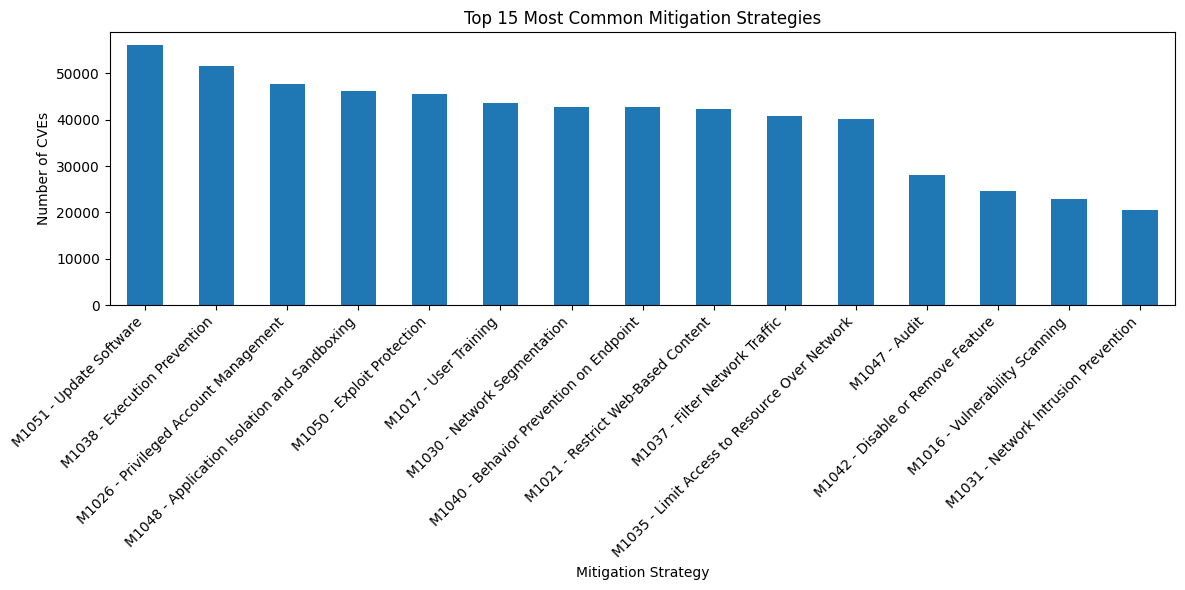

In [ ]:
#Top Mitigations

import matplotlib.pyplot as plt

#Step 1: Flatten mitigation IDs
all_mitigations = df_model["mitigation_ids"].explode()

#Step 2: Get top 15 most common mitigations
top_mitigations = all_mitigations.value_counts().head(15)

#Step 3: Use FULL mapping built earlier
top_mitigations_named = top_mitigations.copy()
top_mitigations_named.index = [
    f"{m} - {mitigation_lookup.get(m, m)}"
    for m in top_mitigations.index
]

#Step 4: Plot
plt.figure(figsize=(12,6))
top_mitigations_named.plot(kind='bar')

plt.title("Top 15 Most Common Mitigation Strategies")
plt.xlabel("Mitigation Strategy")
plt.ylabel("Number of CVEs")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

### Observations from Exploratory Analysis

The exploratory analysis reveals that both CWE classes and mitigation labels are highly imbalanced. A small number of weaknesses and mitigation strategies occur much more frequently than others, while many appear only rarely.

This imbalance is important because machine learning models tend to favor the most common classes, which can lead to biased predictions. As a result, the model may over-predict frequently occurring mitigations while underrepresenting less common but still important ones.

Additionally, the analysis confirms that this is a **multi-label classification problem**, as each CVE can be associated with multiple mitigation strategies. This means the model must be capable of predicting more than one label for a single input, rather than assigning only a single class.

Understanding these characteristics of the dataset is essential for selecting appropriate modeling techniques and evaluation metrics, such as using multi-label classifiers and considering metrics like F1-score or Top-K accuracy instead of simple accuracy.

## 9: Prepare Modeling Datasets

In this section, the dataset is prepared for machine learning by organizing the input features and target labels used for prediction.

The goal of the model is to predict appropriate mitigation strategies for each vulnerability. To achieve this, multiple types of features are combined to capture different aspects of the vulnerability:

- **Text features**: The vulnerability description and associated attack information are combined into a single text field (`combined_text`). This provides contextual information about how the vulnerability works and how it may be exploited.
- **Numerical features**: The CVSS score is included to represent the severity of the vulnerability.
- **Categorical features**: The CVSS severity (used as `threat_level`) and the presence of attack mappings (`has_attack`) provide additional structured information.

The target variable consists of the mitigation strategies associated with each vulnerability. Because a single vulnerability can have multiple applicable mitigations, this is treated as a **multi-label classification problem**. The mitigation labels are transformed into a binary matrix using a technique such as `MultiLabelBinarizer`, where:
- Each column represents a possible mitigation (e.g., M1051 – Update Software)
- Each row indicates whether a mitigation applies to a given vulnerability

This transformation allows the model to predict multiple mitigation strategies simultaneously.

To evaluate the model’s ability to generalize to new data, the dataset is split into training and testing sets. In this project, a time-based split is used:
- The training dataset consists of historical vulnerabilities (e.g., the 100k dataset)
- The testing dataset consists of more recent vulnerabilities (e.g., 2025–2026 data)

This approach better reflects real-world conditions, where models are trained on past data and applied to future threats.

Overall, this step ensures that the data is structured correctly for machine learning, enabling effective training, evaluation, and prediction of mitigation strategies.

## 9.1: Feature Engineering and Dataset Preparation

In this section, the dataset is transformed and structured to make it suitable for machine learning, with a focus on predicting appropriate mitigation strategies for each vulnerability.

Feature engineering involves creating and refining variables that capture meaningful patterns in the data. For this project, the following features are constructed:

- **Text features**: Vulnerability descriptions are combined with enriched attack context into a single feature (`combined_text`). Instead of using raw MITRE ATT&CK technique IDs (e.g., T1059 or T1059.001), these identifiers are converted into descriptive names (e.g., “Command and Scripting Interpreter”). This improves the semantic quality of the text and helps the model better understand attack behavior.
  
- **Numerical features**: The CVSS score is included to represent the severity of each vulnerability.

- **Categorical features**: The CVSS severity is used directly as a threat-level feature (`threat_level`), providing structured information about vulnerability impact.

To improve model performance and reduce noise, rare mitigation labels are filtered out. Only mitigation strategies that appear frequently enough in the dataset are retained, ensuring that the model has sufficient examples to learn meaningful patterns.

Dataset preparation focuses on organizing the data for modeling:

- Input features (`X`) are constructed from the combined text, CVSS score, and threat level
- Target labels (`y`) consist of mitigation strategies associated with each vulnerability
- Because each vulnerability can have multiple mitigations, this is treated as a **multi-label classification problem**
- The mitigation labels are encoded into a binary matrix using `MultiLabelBinarizer`, where each column represents a mitigation and each row indicates whether it applies

The dataset is also structured to support realistic evaluation, with training performed on historical data and testing conducted on more recent vulnerabilities. This reflects real-world deployment, where models must generalize to new and evolving threats.

These steps are essential because machine learning models require structured, meaningful input. By transforming raw cybersecurity data into enriched text features and well-defined labels, this stage ensures that the models can learn effectively and produce accurate mitigation predictions.

Overall, this section bridges the gap between raw data and model-ready input, enabling successful training and evaluation of the cybersecurity prediction system.

In [ ]:
#Main modeling dataset
df_mit = df_model[
    (df_model["has_description"]) &
    (df_model["num_mitigations"] > 0)
].copy()

#Inspect attack source distribution
if "attack_source" in df_mit.columns:
    print("Attack source counts:")
    display(df_mit["attack_source"].value_counts(dropna=False))

#Filter rare mitigation labels
MIN_MITIGATION_SAMPLES = 50

all_mitigation_counts = df_mit["mitigation_ids"].explode().value_counts()

valid_mitigations = set(
    all_mitigation_counts[all_mitigation_counts >= MIN_MITIGATION_SAMPLES].index
)

df_mit["mitigation_ids_filtered"] = df_mit["mitigation_ids"].apply(
    lambda ids: [m for m in ids if m in valid_mitigations]
)

df_mit = df_mit[df_mit["mitigation_ids_filtered"].apply(len) > 0].copy()

#Final features
#Threat level
df_mit["threat_level"] = (
    df_mit["cvss_severity"]
    .fillna("UNKNOWN")
    .astype(str)
    .str.upper()
)

#Convert attack IDs → readable names
attack_lookup = {
    "T1059": "Command and Scripting Interpreter",
    "T1574": "Hijack Execution Flow",
    "T1189": "Drive-by Compromise",
    "T1204": "User Execution",
    "T1055": "Process Injection",
    "T1068": "Exploitation for Privilege Escalation",
    "T1190": "Exploit Public-Facing Application",
    "T1203": "Exploitation for Client Execution"
}

def attack_ids_to_names(ids):
    if not isinstance(ids, list):
        ids = parse_list_cell(ids)

    names = []
    for attack_id in ids:
        parent_id = str(attack_id).split(".")[0].upper()
        if parent_id in attack_lookup:
            names.append(attack_lookup[parent_id])

    return " ".join(names)

#Create readable attack text
if "attack_ids" in df_mit.columns:
    df_mit["attack_name_text"] = df_mit["attack_ids"].apply(attack_ids_to_names)
else:
    df_mit["attack_name_text"] = ""

#Combined text
df_mit["combined_text"] = (
    df_mit["description"].fillna("") + " " +
    df_mit["attack_name_text"].fillna("")
)

#Build mitigation lookup (for readable labels)
mitigation_lookup = {}

for ids, names in zip(df_mit["mitigation_ids"], df_mit["mitigation_names"]):
    if isinstance(ids, list) and isinstance(names, list):
        for m_id, m_name in zip(ids, names):
            #Only keep real names, not placeholders like "M1047"
            if m_name and m_name != m_id:
                mitigation_lookup[m_id] = m_name

#Manual fallback for IDs missing from the dataset names
mitigation_lookup.update({
    "M1013": "Application Developer Guidance",
    "M1015": "Active Directory Configuration",
    "M1016": "Vulnerability Scanning",
    "M1018": "User Account Management",
    "M1019": "Threat Intelligence Program",
    "M1022": "Restrict File and Directory Permissions",
    "M1024": "Restrict Registry Permissions",
    "M1025": "Privileged Process Integrity",
    "M1027": "Password Policies",
    "M1028": "Operating System Configuration",
    "M1029": "Remote Data Storage",
    "M1032": "Multi-factor Authentication",
    "M1033": "Limit Software Installation",
    "M1036": "Account Use Policies",
    "M1039": "Environment Variable Permissions",
    "M1043": "Credential Access Protection",
    "M1044": "Restrict Library Loading",
    "M1045": "Code Signing",
    "M1046": "Boot Integrity",
    "M1047": "Audit",
    "M1049": "Antivirus/Antimalware",
    "M1052": "User Account Control",
    "M1053": "Data Backup",
    "M1054": "Software Configuration",
    "M1056": "Pre-compromise",
    "M1057": "Data Loss Prevention",
    "M1060": "Out-of-Band Communications Channel",
})

#Summary
print("Final modeling rows:", df_mit.shape)
print("Number of mitigation labels:", len(valid_mitigations))

#Readable mitigation distribution
top_mitigations = (
    df_mit["mitigation_ids_filtered"]
    .explode()
    .value_counts()
    .head(15)
)

top_mitigations_named = top_mitigations.copy()
top_mitigations_named.index = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    for m in top_mitigations.index
]

print("\nTop mitigation labels (readable):")
display(top_mitigations_named)

Attack source counts:


,count
attack_source,
bridge,45956
capec,26231


Final modeling rows: (72187, 46)
Number of mitigation labels: 41

Top mitigation labels (readable):


,count
M1051 - Update Software,56054
M1038 - Execution Prevention,51590
M1026 - Privileged Account Management,47649
M1048 - Application Isolation and Sandboxing,46115
M1050 - Exploit Protection,45560
M1017 - User Training,43631
M1030 - Network Segmentation,42773
M1040 - Behavior Prevention on Endpoint,42732
M1021 - Restrict Web-Based Content,42321
M1037 - Filter Network Traffic,40861


## 10: Train Machine Learning Models

In this section, machine learning models are trained to learn the relationship between vulnerability characteristics and their corresponding mitigation strategies.

Using the prepared dataset, the models are trained on a combination of features that capture different aspects of each vulnerability:

- **Text features**: A combined representation of the vulnerability description and associated attack information (`combined_text`)
- **Numerical features**: CVSS score, representing severity
- **Categorical features**: Threat level (CVSS severity) and the presence of attack mappings

These features are processed using a machine learning pipeline, where techniques such as **TF-IDF vectorization** are applied to text data and **encoding methods** (e.g., OneHotEncoder) are applied to categorical variables.

The target variable consists of mitigation strategies, making this a **multi-label classification problem**, where each vulnerability can be associated with multiple mitigations. To handle this, a **One-vs-Rest (OvR)** approach is used, allowing the model to train separate binary classifiers for each mitigation label.

Multiple models are trained and compared, including:

- **Logistic Regression**: A strong baseline model for multi-label classification
- **Random Forest**: A tree-based model capable of capturing non-linear relationships
- **Support Vector Machines (SVM)**: Effective for high-dimensional text data
- **Naive Bayes**: A probabilistic model that performs well on text-based features and serves as a fast, efficient baseline

Each model learns patterns such as how certain vulnerability descriptions, severity levels, and attack characteristics are associated with specific mitigation strategies. This enables the models to generalize and make predictions on previously unseen vulnerabilities.

This step is essential because it builds the core predictive capability of the system, allowing it to automatically recommend appropriate cybersecurity defenses based on learned patterns from historical data.

Comparing multiple models also helps identify which approach performs best for this type of cybersecurity prediction task.

## TF-IDF Feature Representation

In this section, Term Frequency–Inverse Document Frequency (TF-IDF) is used to convert textual vulnerability information into numerical feature vectors that can be used by machine learning models.

TF-IDF measures the importance of words within a document relative to the entire dataset. Words that appear frequently in a specific vulnerability description but are rare across all descriptions are assigned higher weights, while commonly occurring words receive lower weights.

In this project, TF-IDF is applied to a **combined text feature** (`combined_text`), which includes the vulnerability description along with enriched attack context derived from MITRE ATT&CK technique mappings. Instead of using raw attack identifiers (e.g., T1059 or T1059.001), these IDs are converted into meaningful descriptions (e.g., “Command and Scripting Interpreter”), improving the semantic quality of the text.

This transformation is particularly useful for cybersecurity data because vulnerability descriptions often contain key technical terms—such as “buffer overflow,” “privilege escalation,” or “remote code execution”—that strongly indicate appropriate mitigation strategies. Enriching attack techniques further enhances this by adding interpretable context about how vulnerabilities may be exploited.

To improve feature quality, preprocessing steps remove non-informative tokens such as numeric fragments from sub-technique IDs (e.g., “001”, “002”), ensuring that only meaningful terms are included in the TF-IDF representation.

Rather than manually transforming text outside the modeling process, TF-IDF is implemented within a **machine learning pipeline**. This ensures that text vectorization is consistently applied during both training and prediction, improving reproducibility and preventing data leakage.

By converting unstructured text into high-dimensional numerical vectors, TF-IDF enables models such as Logistic Regression, Support Vector Machines (SVM), and Naive Bayes to learn meaningful patterns between vulnerabilities and their associated mitigation strategies.

Overall, TF-IDF serves as a core feature extraction technique in this project, allowing unstructured cybersecurity text data to be effectively utilized in machine learning models while incorporating meaningful attack context.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

#Use combined text (description + attack context)
X_text = df_mit["combined_text"]

#TF-IDF vectorization
tfidf = TfidfVectorizer(max_features=3000, stop_words="english")

X_tfidf = tfidf.fit_transform(X_text)

print("TF-IDF feature matrix shape:", X_tfidf.shape)
print("Number of features (vocabulary size):", len(tfidf.get_feature_names_out()))

TF-IDF feature matrix shape: (72187, 3000)
Number of features (vocabulary size): 3000


In [ ]:
#Inspect Top TF-IDF Terms

import pandas as pd
import numpy as np

feature_names = tfidf.get_feature_names_out()

#Average TF-IDF score for each term
avg_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()


top_terms = pd.DataFrame({
    "term": feature_names,
    "avg_tfidf_score": avg_tfidf
}).sort_values(by="avg_tfidf_score", ascending=False).head(20)
top_terms = top_terms.reset_index()
top_terms.columns = ["term_index", "term", "avg_tfidf_score"]

display(top_terms)

,term_index,term,avg_tfidf_score
0,1059,execution,0.065267
1,1075,exploitation,0.049030
2,2783,user,0.046038
3,2893,vulnerability,0.042019
4,2355,scripting,0.041301
5,1284,hijack,0.037510
6,1148,flow,0.037342
7,1073,exploit,0.034753
8,672,command,0.034622
9,390,application,0.033318


## Print Checks

In this section, print statements are used to verify that data and variables are correctly processed at different stages of the workflow.

These checks help confirm that key components—such as dataset structure, feature transformations, and label encoding—are functioning as expected. For example, printing the shape and type of variables ensures that the input features and target labels are in the correct format for machine learning models.

Print checks are particularly useful for debugging and validation, as they allow potential issues (such as incorrect data types, missing values, or formatting errors) to be identified early in the pipeline.

Although these checks do not directly contribute to the model’s performance, they play an important role in ensuring the reliability and correctness of the overall system.

Overall, this step improves the robustness of the project by verifying that each stage of the data processing and modeling pipeline is working as intended.

In [ ]:
#TF-IDF Feature Representation
from sklearn.feature_extraction.text import TfidfVectorizer

#Use enriched combined text (description + attack names)
X_text = df_mit["combined_text"]

#TF-IDF settings
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words="english",
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]{2,}\b"
)

X_tfidf = tfidf.fit_transform(X_text)

print("TF-IDF shape:", X_tfidf.shape)
print("Number of CVE entries:", X_tfidf.shape[0])
print("Number of TF-IDF features:", X_tfidf.shape[1])

#Show sample vocabulary
print("\nSample TF-IDF features:")
print(tfidf.get_feature_names_out()[:20])

TF-IDF shape: (72187, 3000)
Number of CVE entries: 72187
Number of TF-IDF features: 3000

Sample TF-IDF features:
['ability' 'ability execute' 'able' 'able address' 'able execute'
 'absolute' 'absolute path' 'abuse' 'abused' 'accept' 'accepts' 'access'
 'access control' 'access device' 'access exploitation' 'access files'
 'access filesystem' 'access hijack' 'access sensitive' 'accessed']


## Feature Engineering and Dataset Preparation

This section builds on the preprocessing steps in Section 8.1 by preparing the final inputs for machine learning.

The dataset includes:
- **Combined text features** that integrate vulnerability descriptions with enriched attack context
- **Structured features** such as CVSS severity (threat level)
- **Filtered multi-label targets** representing mitigation strategies

These transformations ensure that the data is clean, informative, and ready for model training.

## Train/Test Split

In this section, the dataset is divided into two subsets: a training set and a testing set.

The training set is used to train the machine learning models, allowing them to learn patterns between vulnerability characteristics and their associated mitigation strategies. The testing set is used to evaluate how well the trained models perform on unseen data.

In this project, a **time-based split** is used rather than a random split. The training dataset consists of historical vulnerabilities, while the testing dataset contains more recent vulnerabilities (e.g., from 2025–2026).

This approach more closely reflects real-world conditions, where models are trained on past data and applied to predict outcomes for newly discovered vulnerabilities.

Using a time-based split helps ensure that the evaluation is realistic and prevents data leakage from future information into the training process.

Overall, this step is essential for building reliable machine learning models that can generalize effectively to new and evolving cybersecurity threats.

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
import pandas as pd

#Training features
X_train = df_mit[[
    "combined_text",
    "cvss_score",
    "threat_level"
]].copy()

#Multi-label target
mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(df_mit["mitigation_ids_filtered"])

#Build mitigation lookup (dynamic + fallback)
mitigation_lookup = {}

for ids, names in zip(df_mit["mitigation_ids"], df_mit["mitigation_names"]):
    if isinstance(ids, list) and isinstance(names, list):
        for m_id, m_name in zip(ids, names):
            if m_name and m_name != m_id:
                mitigation_lookup[m_id] = m_name

#Add missing known mappings (fallback)
mitigation_lookup.update({
    "M1013": "Application Developer Guidance",
    "M1015": "Active Directory Configuration",
    "M1016": "Vulnerability Scanning",
    "M1018": "User Account Management",
    "M1019": "Threat Intelligence Program",
    "M1022": "Restrict File and Directory Permissions",
    "M1024": "Restrict Registry Permissions",
    "M1025": "Privileged Process Integrity",
    "M1027": "Password Policies",
    "M1028": "Operating System Configuration",
    "M1029": "Remote Data Storage",
    "M1032": "Multi-factor Authentication",
    "M1033": "Limit Software Installation",
    "M1036": "Account Use Policies",
    "M1039": "Environment Variable Permissions",
    "M1043": "Credential Access Protection",
    "M1044": "Restrict Library Loading",
    "M1045": "Code Signing",
    "M1046": "Boot Integrity",
    "M1047": "Audit",
    "M1049": "Antivirus/Antimalware",
    "M1052": "User Account Control",
    "M1053": "Data Backup",
    "M1054": "Software Configuration",
    "M1056": "Pre-compromise",
    "M1057": "Data Loss Prevention",
    "M1060": "Out-of-Band Communications Channel",
})

#Create readable labels
mitigation_labels_readable = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    for m in mlb.classes_
]

#Print summary
print("Training feature shape:", X_train.shape)
print("Training label shape:", y_train.shape)
print("Number of mitigation labels:", len(mlb.classes_))

print("\nReadable Mitigation Labels:")
for label in mitigation_labels_readable:
    print(label)

#Clean table view
mitigation_labels_df = pd.DataFrame({
    "mitigation_id": mlb.classes_,
    "mitigation_name": [mitigation_lookup.get(m, "Unknown Mitigation") for m in mlb.classes_]
})

display(mitigation_labels_df)

Training feature shape: (72187, 3)
Training label shape: (72187, 41)
Number of mitigation labels: 41

Readable Mitigation Labels:
M1013 - Application Developer Guidance
M1015 - Active Directory Configuration
M1016 - Vulnerability Scanning
M1017 - User Training
M1018 - User Account Management
M1019 - Threat Intelligence Program
M1021 - Restrict Web-Based Content
M1022 - Restrict File and Directory Permissions
M1024 - Restrict Registry Permissions
M1025 - Privileged Process Integrity
M1026 - Privileged Account Management
M1027 - Password Policies
M1028 - Operating System Configuration
M1029 - Remote Data Storage
M1030 - Network Segmentation
M1031 - Network Intrusion Prevention
M1032 - Multi-factor Authentication
M1033 - Limit Software Installation
M1035 - Limit Access to Resource Over Network
M1036 - Account Use Policies
M1037 - Filter Network Traffic
M1038 - Execution Prevention
M1039 - Environment Variable Permissions
M1040 - Behavior Prevention on Endpoint
M1041 - Encrypt Sensitive In

,mitigation_id,mitigation_name
0,M1013,Application Developer Guidance
1,M1015,Active Directory Configuration
2,M1016,Vulnerability Scanning
3,M1017,User Training
4,M1018,User Account Management
5,M1019,Threat Intelligence Program
6,M1021,Restrict Web-Based Content
7,M1022,Restrict File and Directory Permissions
8,M1024,Restrict Registry Permissions
9,M1025,Privileged Process Integrity


## 10.1: Model 1~ Logistic Regression

In this section, a Logistic Regression model is trained to predict mitigation strategies for vulnerabilities based on both textual and structured features.

Logistic Regression is a linear classification algorithm that estimates the probability of each mitigation label being relevant to a given input. Because each vulnerability can be associated with multiple mitigation strategies, the model is implemented using a **One-vs-Rest (OvR)** approach. This allows the model to treat each mitigation as an independent binary classification problem, enabling multi-label prediction.

The model uses a combination of features:

- **Text features**: A TF-IDF representation of the `combined_text`, which includes vulnerability descriptions enriched with meaningful MITRE ATT&CK technique names
- **Numerical features**: CVSS score, representing the severity of the vulnerability
- **Categorical features**: Threat level derived from CVSS severity

These features are processed within a **machine learning pipeline**, ensuring consistent preprocessing (e.g., TF-IDF vectorization and encoding) during both training and prediction.

Logistic Regression is a strong baseline model for this task because it performs well with high-dimensional text data, is computationally efficient, and provides interpretable results. It serves as a useful benchmark for comparison with more complex models such as Support Vector Machines, Random Forests, and Naive Bayes.

By learning patterns between vulnerability characteristics and mitigation strategies, the model can recommend appropriate defensive actions for previously unseen vulnerabilities.

Overall, this model establishes a baseline for evaluating the effectiveness of machine learning in predicting cybersecurity mitigations.

## Train Logistic Regression Model

In this section, a Logistic Regression model is trained to predict mitigation strategies for vulnerabilities using both textual and structured features.

The model is trained on a combination of:
- **TF-IDF features** derived from the `combined_text`, which includes vulnerability descriptions enriched with MITRE ATT&CK technique names
- **Numerical features** such as the CVSS score
- **Categorical features** such as the threat level derived from CVSS severity

Because each vulnerability can have multiple applicable mitigation strategies, this task is treated as a **multi-label classification problem**. To handle this, the Logistic Regression model is applied using a **One-vs-Rest (OvR)** approach, where a separate binary classifier is trained for each mitigation label.

All preprocessing steps, including TF-IDF vectorization and feature encoding, are handled within a machine learning pipeline. This ensures consistency between training and prediction while preventing data leakage.

During training, the model learns patterns that link vulnerability characteristics to appropriate mitigation strategies. This enables it to recommend multiple relevant defenses for previously unseen vulnerabilities.

Overall, this step builds the core predictive model used to automatically suggest cybersecurity mitigation strategies based on vulnerability data.

In [ ]:
#Create combined_text if it does not exist
df["combined_text"] = (
    df["description"].astype(str) + " " +
    df["cve_id"].astype(str)
)

#Create threat_level from CVSS score
def get_threat_level(score):
    if score >= 9.0:
        return "Critical"
    elif score >= 7.0:
        return "High"
    elif score >= 4.0:
        return "Medium"
    else:
        return "Low"

df["threat_level"] = df["cvss_score"].apply(get_threat_level)

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

#Features
X = df[["combined_text", "cvss_score", "threat_level"]]

#Only keep columns that are truly binary 0/1 numeric labels
mitigation_columns = []

for col in df.columns:
    values = df[col].dropna()

    if pd.api.types.is_numeric_dtype(values):
        unique_values = set(values.unique())

        if unique_values.issubset({0, 1}) and len(unique_values) > 0:
            mitigation_columns.append(col)

#Labels must be numeric integers
y = df[mitigation_columns].fillna(0).astype(int)

#Remove labels with no positive samples
valid_labels = y.sum(axis=0) > 0
y = y.loc[:, valid_labels]

print("Final label count after filtering:", y.shape[1])

#Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Mitigation columns found:", mitigation_columns)
print("y dtypes:")
print(y.dtypes)

Final label count after filtering: 5
X shape: (72193, 3)
y shape: (72193, 5)
Mitigation columns found: ['is_kev', 'has_patch', 'has_exploit', 'has_attack', 'has_description']
y dtypes:
is_kev             int64
has_patch          int64
has_exploit        int64
has_attack         int64
has_description    int64
dtype: object


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

#Feature processing
preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(
            max_features=3000,
            stop_words="english",
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]{2,}\b"
        ), "combined_text"),

        ("num", SimpleImputer(strategy="median"), ["cvss_score"]),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), ["threat_level"])
    ]
)

#Model (multi-label)
model_log = Pipeline([
    ("preprocess", preprocessor),
    ("clf", OneVsRestClassifier(
        LogisticRegression(max_iter=3000, random_state=42)
    ))
])

#Train model
model_log.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label 3 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/multiclass.py:90: UserWarning: Label 4 is present in all training examples.
  warnings.warn(


In [ ]:
from sklearn.metrics import f1_score
import numpy as np

#Predict with Logistic Regression
y_pred_log = model_log.predict(X_test)

#Convert to numpy
y_test_array = np.asarray(y_test)
y_pred_array = np.asarray(y_pred_log)

#Check and align label counts if needed
print("y_test shape:", y_test_array.shape)
print("y_pred_log shape:", y_pred_array.shape)

if y_test_array.shape[1] != y_pred_array.shape[1]:
    print("Warning: y_test and y_pred_log have different label counts. Aligning to smaller size.")
    n_labels = min(y_test_array.shape[1], y_pred_array.shape[1])
    y_test_array = y_test_array[:, :n_labels]
    y_pred_array = y_pred_array[:, :n_labels]

#F1 scores
log_micro_f1 = f1_score(y_test_array, y_pred_array, average="micro", zero_division=0)
log_macro_f1 = f1_score(y_test_array, y_pred_array, average="macro", zero_division=0)

print("Logistic Regression Micro F1:", round(log_micro_f1, 4))
print("Logistic Regression Macro F1:", round(log_macro_f1, 4))

#Get probability scores
X_processed = model_log.named_steps["preprocess"].transform(X_test)

probs = []
for clf in model_log.named_steps["clf"].estimators_:
    if hasattr(clf, "predict_proba") and hasattr(clf, "classes_") and len(clf.classes_) == 2:
        probs.append(clf.predict_proba(X_processed)[:, 1])
    else:
        probs.append(np.zeros(X_processed.shape[0]))

log_probs = np.array(probs).T

#Align probabilities if needed
if log_probs.shape[1] != y_test_array.shape[1]:
    n_labels = min(log_probs.shape[1], y_test_array.shape[1])
    log_probs = log_probs[:, :n_labels]
    y_test_array = y_test_array[:, :n_labels]

#Top-K function
def top_k_accuracy_multilabel(y_true, probs, k):
    y_true = np.asarray(y_true)

    correct = 0
    for i in range(len(y_true)):
        top_k = np.argsort(probs[i])[-k:]
        true_labels = np.where(y_true[i] == 1)[0]

        if any(label in top_k for label in true_labels):
            correct += 1

    return correct / len(y_true)

#Top-K scores
log_top3 = top_k_accuracy_multilabel(y_test_array, log_probs, 3)
log_top5 = top_k_accuracy_multilabel(y_test_array, log_probs, 5)

print("Logistic Regression Top-3 Accuracy:", round(log_top3, 4))
print("Logistic Regression Top-5 Accuracy:", round(log_top5, 4))

y_test shape: (14439, 5)
y_pred_log shape: (14439, 5)
Logistic Regression Micro F1: 0.9307
Logistic Regression Macro F1: 0.6616
Logistic Regression Top-3 Accuracy: 0.5282
Logistic Regression Top-5 Accuracy: 1.0


## Evaluate Logistic Regression Model

In this section, the performance of the trained Logistic Regression model is evaluated to assess how well it predicts mitigation strategies for vulnerabilities.

Because this project focuses on **multi-label classification**, where each vulnerability can have multiple associated mitigation strategies, traditional accuracy alone is not sufficient. Instead, more appropriate evaluation metrics are used.

The primary metrics include:

- **Precision**: Measures how many predicted mitigation strategies are actually correct
- **Recall**: Measures how well the model identifies all relevant mitigation strategies
- **F1-Score**: A balanced metric that combines precision and recall

Two types of F1-scores are reported:

- **Micro F1-score**: Aggregates contributions from all labels and is useful when dealing with imbalanced data
- **Macro F1-score**: Computes the metric independently for each label and averages them, treating all mitigation strategies equally

A **classification report** is generated to provide a detailed breakdown of precision, recall, and F1-score for each mitigation label.

In addition to standard metrics, the evaluation also considers the **average number of predicted mitigations per vulnerability**, which helps assess whether the model is over-predicting or under-predicting labels.

This evaluation is initially performed on the training dataset to verify that the model has learned meaningful patterns. For a more realistic assessment, the model can also be evaluated on a separate test dataset containing newer vulnerabilities.

Overall, this step determines how effectively the model can recommend appropriate mitigation strategies and provides a baseline for comparison with other models.

In [ ]:
from sklearn.metrics import classification_report

#Predict on test data
y_pred = model_log.predict(X_test)

#Use the actual label columns from y_test
target_names = list(y_test.columns)

print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    zero_division=0
))

print("\nAverage number of true mitigations per CVE:",
      y_test.sum(axis=1).mean())

print("Average number of predicted mitigations per CVE:",
      y_pred.sum(axis=1).mean())

Classification Report:

                 precision    recall  f1-score   support

         is_kev       0.00      0.00      0.00        95
      has_patch       0.75      0.45      0.56      3585
    has_exploit       0.78      0.71      0.74      5070
     has_attack       1.00      1.00      1.00     14439
has_description       1.00      1.00      1.00     14439

      micro avg       0.96      0.91      0.93     37628
      macro avg       0.71      0.63      0.66     37628
   weighted avg       0.94      0.91      0.92     37628
    samples avg       0.97      0.93      0.94     37628


Average number of true mitigations per CVE: 2.6059976452662927
Average number of predicted mitigations per CVE: 2.46976937461043


## 10.2: Model 2~ Random Forest

In this section, a Random Forest model is trained to predict mitigation strategies for vulnerabilities using both textual and structured features.

Random Forest is an ensemble learning algorithm that builds multiple decision trees and combines their predictions to improve accuracy and reduce overfitting. Each tree is trained on a random subset of the data and features, and the final prediction is determined by aggregating the outputs of all trees.

In this project, the model uses a combination of features:

- **Text features**: TF-IDF representation of the `combined_text`, which includes vulnerability descriptions enriched with MITRE ATT&CK technique names  
- **Numerical features**: CVSS score, representing vulnerability severity  
- **Categorical features**: Threat level derived from CVSS severity  

Because each vulnerability can have multiple associated mitigation strategies, this task is treated as a **multi-label classification problem**. A **One-vs-Rest (OvR)** approach is used so that the model can independently predict each mitigation label.

All preprocessing steps, including TF-IDF vectorization and categorical encoding, are handled within a machine learning pipeline to ensure consistency between training and prediction.

Unlike linear models such as Logistic Regression and Support Vector Machines, Random Forest can capture **non-linear relationships** between features. This allows it to identify more complex patterns in vulnerability data, including interactions between severity, attack behavior, and textual descriptions.

However, Random Forest models may be less efficient when working with high-dimensional sparse data like TF-IDF and can require more computational resources compared to linear models.

The model is evaluated using multi-label metrics such as precision, recall, and F1-score to assess how effectively it predicts mitigation strategies.

Overall, this model provides a valuable comparison to linear approaches and helps determine whether non-linear methods improve the prediction of cybersecurity mitigation strategies.

## Train Random Forest Model

In this section, the Random Forest model is trained using the prepared dataset to predict mitigation strategies for vulnerabilities.

The model is trained on a combination of features that capture both textual and structured information:

- **Text features**: TF-IDF representations of the `combined_text`, which includes vulnerability descriptions enriched with MITRE ATT&CK technique names  
- **Numerical features**: CVSS score, representing the severity of each vulnerability  
- **Categorical features**: Threat level derived from CVSS severity  

All feature transformations, including TF-IDF vectorization and categorical encoding, are handled within a machine learning pipeline to ensure consistent preprocessing during both training and prediction.

Because this is a **multi-label classification problem**, where each vulnerability can have multiple associated mitigation strategies, the Random Forest model is applied using a **One-vs-Rest (OvR)** approach. This allows the model to independently learn each mitigation label as a separate binary classification task.

Random Forest works by constructing an ensemble of decision trees, where each tree is trained on a random subset of the data and features. The final prediction is made by aggregating the outputs of all trees, which improves robustness and reduces overfitting.

Unlike linear models, Random Forest can capture **non-linear relationships** between features. This enables it to learn more complex interactions between vulnerability descriptions, severity scores, and attack characteristics.

This step is important because it provides an alternative modeling approach and allows comparison of performance across different algorithms. By training the Random Forest model, the project evaluates whether ensemble methods can improve the prediction of cybersecurity mitigation strategies.

Overall, this training process builds a model capable of recommending multiple mitigation strategies for previously unseen vulnerabilities based on learned patterns in the data.

In [ ]:
#Random Forest Data Prep

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
import pandas as pd
import ast

#Use df_model if it exists; otherwise fall back to df
data = df_model.copy() if "df_model" in globals() else df.copy()

#Helper: safely convert cells into lists
def parse_list_cell(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    if isinstance(value, str):
        value = value.strip()

        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list):
                return parsed
        except:
            pass

        if "," in value:
            return [item.strip() for item in value.split(",") if item.strip()]

        if value:
            return [value]

    return []

#Pick mitigation label source
if "mitigation_ids" in data.columns:
    mitigation_source_col = "mitigation_ids"
elif "mitigation_names" in data.columns:
    mitigation_source_col = "mitigation_names"
else:
    raise ValueError("No mitigation_ids or mitigation_names column found.")

print("Using mitigation source column:", mitigation_source_col)

#Clean required feature columns
required_features = ["combined_text", "cvss_score", "threat_level"]

if "combined_text" not in data.columns:
    data["combined_text"] = data["description"].fillna("").astype(str)

if "threat_level" not in data.columns:
    def get_threat_level(score):
        if score >= 9.0:
            return "Critical"
        elif score >= 7.0:
            return "High"
        elif score >= 4.0:
            return "Medium"
        else:
            return "Low"

    data["cvss_score"] = pd.to_numeric(data["cvss_score"], errors="coerce")
    data["threat_level"] = data["cvss_score"].apply(get_threat_level)

data["combined_text"] = data["combined_text"].fillna("").astype(str)
data["cvss_score"] = pd.to_numeric(data["cvss_score"], errors="coerce")
data["cvss_score"] = data["cvss_score"].fillna(data["cvss_score"].median())
data["threat_level"] = data["threat_level"].fillna("Unknown").astype(str)

#Convert mitigations into list format
data["mitigation_list"] = data[mitigation_source_col].apply(parse_list_cell)

#Remove rows with no mitigation labels
data = data[data["mitigation_list"].apply(len) > 0].copy()

#Multi-label encode targets
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(data["mitigation_list"])

mitigation_columns = list(mlb.classes_)
y = pd.DataFrame(y_encoded, columns=mitigation_columns, index=data.index)

#Features
X = data[["combined_text", "cvss_score", "threat_level"]].copy()

#Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

#Readable mitigation labels
mitigation_labels_readable = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    if "mitigation_lookup" in globals()
    else m
    for m in mitigation_columns
]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Number of mitigation labels:", len(mitigation_columns))
print("Example labels:", mitigation_labels_readable[:10])

Using mitigation source column: mitigation_ids
X_train shape: (57749, 3)
X_test shape: (14438, 3)
y_train shape: (57749, 43)
y_test shape: (14438, 43)
Number of mitigation labels: 43
Example labels: ['M1013 - Application Developer Guidance', 'M1015 - Active Directory Configuration', 'M1016 - Vulnerability Scanning', 'M1017 - User Training', 'M1018 - User Account Management', 'M1019 - Threat Intelligence Program', 'M1020 - Unknown Mitigation', 'M1021 - Restrict Web-Based Content', 'M1022 - Restrict File and Directory Permissions', 'M1024 - Restrict Registry Permissions']


## Evaluate Random Forest Model

In this section, the performance of the trained Random Forest model is evaluated to assess how well it predicts mitigation strategies for vulnerabilities.

Because this project involves **multi-label classification**, where each vulnerability may have multiple valid mitigation strategies, evaluation requires metrics that go beyond traditional accuracy.

The model is evaluated using the following metrics:

- **Precision**: Measures how many predicted mitigation strategies are actually correct  
- **Recall**: Measures how well the model identifies all relevant mitigation strategies  
- **F1-Score**: A balanced metric that combines precision and recall  

A detailed **classification report** is generated to show these metrics for each mitigation label, providing insight into how well the model performs across different types of defenses.

In addition to standard metrics, **Top-K evaluation** is used to better reflect real-world recommendation scenarios:

- **Top-3 Accuracy**: Checks whether at least one correct mitigation appears in the top 3 predicted strategies  
- **Top-5 Accuracy**: Checks whether at least one correct mitigation appears in the top 5 predictions  

Top-K evaluation is particularly useful in cybersecurity, where recommending several relevant mitigation strategies is more practical than predicting a single exact label.

The evaluation also considers the **average number of predicted mitigations per vulnerability**, helping determine whether the model tends to over-predict or under-predict mitigation strategies.

This evaluation is initially performed on the training dataset to verify that the model has learned meaningful patterns. For a more realistic assessment, the model can also be evaluated on a separate test dataset containing newer vulnerabilities.

Overall, this step determines how effectively the Random Forest model can recommend appropriate mitigation strategies and provides a basis for comparison with other models such as Logistic Regression and Naive Bayes.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

#Build preprocessor specifically for Random Forest
preprocessor_rf = ColumnTransformer([
    #Text → TF-IDF
    ("text", TfidfVectorizer(
        max_features=3000,
        stop_words="english"
    ), "combined_text"),

    #Categorical → One-hot
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["threat_level"]),

    #Numeric → Passthrough
    ("num", "passthrough", ["cvss_score"])
])

#Random Forest Pipeline
rf_model = Pipeline([
    ("preprocess", preprocessor_rf),
    ("clf", RandomForestClassifier(
        n_estimators=200,        #slightly stronger than default
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ))
])

#Train
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score, classification_report, hamming_loss, accuracy_score

# Use the correct trained model variable name
# Change this if your actual model is named differently
model_rf = rf_model

# True labels
y_true = y_test.to_numpy() if hasattr(y_test, "to_numpy") else np.asarray(y_test)

# Predictions
y_pred = rf_model.predict(X_test)

# Probabilities
y_probs_raw = rf_model.predict_proba(X_test)

# Handle OneVsRestClassifier / MultiOutputClassifier probability output
if isinstance(y_probs_raw, list):
    y_probs = np.column_stack([
        p[:, 1] if p.shape[1] > 1 else np.zeros(p.shape[0])
        for p in y_probs_raw
    ])
else:
    y_probs = y_probs_raw

# Top-K Accuracy for multilabel classification
def top_k_accuracy_multilabel(y_true, y_probs, k):
    correct = 0
    total = y_true.shape[0]

    for i in range(total):
        top_k_preds = np.argsort(y_probs[i])[-k:]

        if np.any(y_true[i, top_k_preds] == 1):
            correct += 1

    return correct / total

rf_top3 = top_k_accuracy_multilabel(y_true, y_probs, 3)
rf_top5 = top_k_accuracy_multilabel(y_true, y_probs, 5)

# F1 scores
rf_micro_f1 = f1_score(y_true, y_pred, average="micro", zero_division=0)
rf_macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

# Extra multilabel metrics
rf_hamming = hamming_loss(y_true, y_pred)
rf_exact_match = accuracy_score(y_true, y_pred)

# Store results
randForest_results = pd.Series({
    "Top-3 Accuracy": round(rf_top3, 4),
    "Top-5 Accuracy": round(rf_top5, 4),
    "Micro F1": round(rf_micro_f1, 4),
    "Macro F1": round(rf_macro_f1, 4),
    "Hamming Loss": round(rf_hamming, 4),
    "Exact Match Accuracy": round(rf_exact_match, 4)
})

print(randForest_results)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=mlb.classes_,
    zero_division=0
))

Top-3 Accuracy          0.9997
Top-5 Accuracy          0.9997
Micro F1                0.9983
Macro F1                0.9474
Hamming Loss            0.0009
Exact Match Accuracy    0.9868
dtype: float64

Classification Report:
              precision    recall  f1-score   support

       M1013       1.00      0.99      1.00      1423
       M1015       1.00      0.97      0.98       293
       M1016       1.00      1.00      1.00      4493
       M1017       1.00      1.00      1.00      8687
       M1018       1.00      0.99      1.00      3163
       M1019       1.00      1.00      1.00      3611
       M1020       0.00      0.00      0.00         2
       M1021       1.00      1.00      1.00      8468
       M1022       1.00      1.00      1.00      3834
       M1024       1.00      0.99      0.99       777
       M1025       1.00      0.96      0.98       428
       M1026       1.00      1.00      1.00      9518
       M1027       1.00      0.99      0.99      1629
       M1028      

## Show Example Predictions

In this section, example predictions generated by the trained model are displayed to illustrate how the system performs on individual vulnerability descriptions.

A small sample of vulnerabilities is selected, and the model outputs the **top predicted mitigation strategies (Top-K)** for each case. These predictions are ranked based on confidence, allowing the most relevant mitigation strategies to appear first.

Because this project involves **multi-label classification**, each vulnerability may have multiple correct mitigation strategies. Instead of predicting a single label, the model recommends several likely defenses, providing a more realistic and practical approach to cybersecurity decision-making.

This step is important because it provides a concrete, human-readable demonstration of the model’s capabilities. While evaluation metrics such as F1-score and Top-K accuracy quantify performance, example predictions show how the model behaves in real-world scenarios.

By comparing the **actual mitigation strategies** with the **top predicted recommendations**, it is possible to assess whether the model is identifying relevant and meaningful defenses. This also helps reveal strengths and weaknesses, such as whether the model favors common mitigations or misses more specific ones.

Overall, this section bridges the gap between quantitative evaluation and practical application, demonstrating how the system can be used to support real-world cybersecurity defense recommendations.

In [ ]:
#Show Example Mitigation Predictions (Top-3 & Top-5)
import pandas as pd
import numpy as np

example_model = rf_model

#Get probabilities
y_probs_raw = example_model.predict_proba(X_test)

#Convert to matrix
if isinstance(y_probs_raw, list):
    y_probs = []

    for p in y_probs_raw:
        if p.shape[1] > 1:
            y_probs.append(p[:, 1])
        else:
            y_probs.append(p[:, 0])

    y_probs = np.array(y_probs).T
else:
    y_probs = y_probs_raw

#Labels
mitigation_labels = list(y_test.columns)

def readable_mitigation(m_id):
    return f"{m_id} - {mitigation_lookup.get(m_id, 'Unknown Mitigation')}"

def get_top_k(probabilities, k):
    indices = np.argsort(probabilities)[-k:][::-1]
    return [readable_mitigation(mitigation_labels[i]) for i in indices]

#Show examples
num_examples = 5
examples = []

for i in range(min(num_examples, len(X_test))):

    true_labels = [
        readable_mitigation(mitigation_labels[j])
        for j in range(y_test.shape[1])
        if y_test.iloc[i, j] == 1
    ]

    top3 = get_top_k(y_probs[i], 3)
    top5 = get_top_k(y_probs[i], 5)

    examples.append({
        "Description": X_test["combined_text"].iloc[i][:150] + "...",
        "Actual Mitigations": ", ".join(true_labels),
        "Predicted Top-3": ", ".join(top3),
        "Predicted Top-5": ", ".join(top5)
    })

examples_df = pd.DataFrame(examples)

print("Example Mitigation Predictions:")
display(examples_df)

Example Mitigation Predictions:


,Description,Actual Mitigations,Predicted Top-3,Predicted Top-5
0,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...","M1013 - Application Developer Guidance, M1017 - User Training, M1018 - User Account Management, M1021 - Restrict Web...","M1051 - Update Software, M1026 - Privileged Account Management, M1018 - User Account Management","M1051 - Update Software, M1026 - Privileged Account Management, M1018 - User Account Management, M1047 - Audit, M103..."
1,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,M1037 - Filter Network Traffic,"M1037 - Filter Network Traffic, M1047 - Audit, M1051 - Update Software","M1037 - Filter Network Traffic, M1047 - Audit, M1051 - Update Software, M1022 - Restrict File and Directory Permissi..."
2,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,"M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software, M1056 - Pre-compr..."
3,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...","M1016 - Vulnerability Scanning, M1026 - Privileged Account Management, M1030 - Network Segmentation, M1035 - Limit A...","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software, M1037 - Filter Ne..."
4,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,"M1018 - User Account Management, M1047 - Audit, M1052 - User Account Control","M1047 - Audit, M1018 - User Account Management, M1052 - User Account Control","M1047 - Audit, M1018 - User Account Management, M1052 - User Account Control, M1022 - Restrict File and Directory Pe..."


## 10.3: Model 3~ Linear Support Vector Machine (SVM)

In this section, a Linear Support Vector Machine (SVM) model is trained to predict mitigation strategies for vulnerabilities using both textual and structured features.

Linear SVM is a classification algorithm that identifies the optimal boundary (hyperplane) that separates classes in a high-dimensional feature space. It is particularly well-suited for this project because TF-IDF representations of text data are **sparse and high-dimensional**, which is where linear SVM models typically perform very well.

The model uses a combination of features:

- **Text features**: TF-IDF representation of the `combined_text`, which includes vulnerability descriptions enriched with MITRE ATT&CK technique names  
- **Numerical features**: CVSS score, representing vulnerability severity  
- **Categorical features**: Threat level derived from CVSS severity  

All preprocessing steps, including TF-IDF vectorization and categorical encoding, are handled within a machine learning pipeline to ensure consistency during both training and prediction.

Because each vulnerability can have multiple associated mitigation strategies, this task is treated as a **multi-label classification problem**. A **One-vs-Rest (OvR)** approach is used, where a separate binary classifier is trained for each mitigation label, allowing the model to recommend multiple relevant defenses.

Unlike Logistic Regression, Linear SVM does not directly output probabilities but instead focuses on maximizing the margin between classes. This often results in strong performance for text classification tasks, especially when the data is linearly separable in high-dimensional space.

Linear SVM is also computationally efficient compared to non-linear models and can scale well to large cybersecurity datasets.

Overall, this model provides a powerful and efficient approach for predicting mitigation strategies and serves as a strong benchmark for comparison with other models such as Logistic Regression, Random Forest, and Naive Bayes.

## Train Linear SVM Model

In this section, a Linear Support Vector Machine (SVM) model is trained to predict mitigation strategies for vulnerabilities using both textual and structured features.

The model is trained on a combination of:

- **Text features**: TF-IDF representation of the `combined_text`, which includes vulnerability descriptions enriched with MITRE ATT&CK technique names  
- **Numerical features**: CVSS score, representing the severity of each vulnerability  
- **Categorical features**: Threat level derived from CVSS severity  

All feature transformations, including TF-IDF vectorization and categorical encoding, are handled within a machine learning pipeline to ensure consistent preprocessing during both training and prediction.

Because this is a **multi-label classification problem**, where each vulnerability can have multiple associated mitigation strategies, the Linear SVM model is applied using a **One-vs-Rest (OvR)** approach. This allows the model to train a separate binary classifier for each mitigation label and recommend multiple relevant defenses for a single vulnerability.

Linear SVM is particularly well-suited for this task because it performs effectively on **high-dimensional, sparse data**, such as TF-IDF representations of text. By maximizing the margin between classes, the model learns clear decision boundaries that separate relevant and irrelevant mitigation strategies.

Unlike probabilistic models, Linear SVM does not directly output probabilities, but it is often highly effective for text classification tasks due to its ability to generalize well in large feature spaces.

This step is important because it enables the system to automatically recommend appropriate cybersecurity mitigation strategies based on patterns learned from historical vulnerability data.

Overall, this training process builds a robust and efficient model for predicting multiple mitigation strategies for previously unseen vulnerabilities.

In [ ]:
#Train + Evaluate Linear SVM (Multi-label Pipeline)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score
import numpy as np

#Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(
            max_features=3000,
            stop_words="english",
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]{2,}\b"
        ), "combined_text"),

        ("num", "passthrough", ["cvss_score"]),

        ("cat", OneHotEncoder(handle_unknown="ignore"), ["threat_level"])
    ]
)

#Linear SVM Model (OvR)
model_svm = Pipeline([
    ("preprocess", preprocessor),
    ("clf", OneVsRestClassifier(
        LinearSVC(random_state=42, max_iter=2000)
    ))
])

#Train model
model_svm.fit(X_train, y_train)

print("✅ Linear SVM model trained successfully.")
print("Training samples:", X_train.shape[0])
print("Number of mitigation labels:", len(mlb.classes_))


#Evaluation
#Predictions
y_pred_svm = model_svm.predict(X_train)

#F1 Scores
svm_micro_f1 = f1_score(y_train, y_pred_svm, average="micro", zero_division=0)
svm_macro_f1 = f1_score(y_train, y_pred_svm, average="macro", zero_division=0)

#Readable labels
mitigation_labels_readable = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    for m in mlb.classes_
]

print("\n📊 Linear SVM Results")
print("Micro F1:", round(svm_micro_f1, 4))
print("Macro F1:", round(svm_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_train,
    y_pred_svm,
    target_names=mitigation_labels_readable,
    zero_division=0
))

#NOTE ABOUT TOP-K
print("\nNote:")
print("Linear SVM does not provide probabilities, so Top-K evaluation is not used.")

✅ Linear SVM model trained successfully.
Training samples: 57749
Number of mitigation labels: 43

📊 Linear SVM Results
Micro F1: 0.9991
Macro F1: 0.9884

Classification Report:
                                                 precision    recall  f1-score   support

         M1013 - Application Developer Guidance       1.00      1.00      1.00      5936
         M1015 - Active Directory Configuration       1.00      1.00      1.00      1140
                 M1016 - Vulnerability Scanning       1.00      1.00      1.00     18382
                          M1017 - User Training       1.00      1.00      1.00     34944
                M1018 - User Account Management       1.00      1.00      1.00     12430
            M1019 - Threat Intelligence Program       1.00      1.00      1.00     14360
                     M1020 - Unknown Mitigation       1.00      0.80      0.89         5
             M1021 - Restrict Web-Based Content       1.00      1.00      1.00     33853
M1022 - Restrict File

## Evaluate Linear SVM Model

In this section, the performance of the trained Linear Support Vector Machine (SVM) model is evaluated to assess how well it predicts mitigation strategies for vulnerabilities.

Because this project involves **multi-label classification**, where each vulnerability may have multiple valid mitigation strategies, evaluation focuses on metrics that capture both correctness and completeness of the predictions.

The primary evaluation metrics include:

- **Precision**: Measures how many predicted mitigation strategies are actually correct  
- **Recall**: Measures how well the model identifies all relevant mitigation strategies  
- **F1-Score**: A balanced metric that combines precision and recall  

Two types of F1-scores are reported:

- **Micro F1-score**: Aggregates contributions from all labels and is useful when dealing with imbalanced data  
- **Macro F1-score**: Computes the metric independently for each label and averages them, treating all mitigation strategies equally  

A **classification report** is generated to provide a detailed breakdown of these metrics for each mitigation label, offering insight into the model’s performance across different types of defenses.

Unlike models such as Logistic Regression and Random Forest, Linear SVM does not directly produce probability estimates. As a result, **Top-K evaluation (e.g., Top-3 or Top-5 accuracy) is not used** for this model. Instead, performance is assessed based on how accurately the model predicts the full set of relevant mitigation strategies.

This evaluation helps determine how effectively the Linear SVM model can recommend appropriate cybersecurity defenses and provides a basis for comparison with other models.

Overall, this step ensures that the model is capable of identifying meaningful mitigation strategies based on vulnerability data, even without probabilistic ranking of predictions.

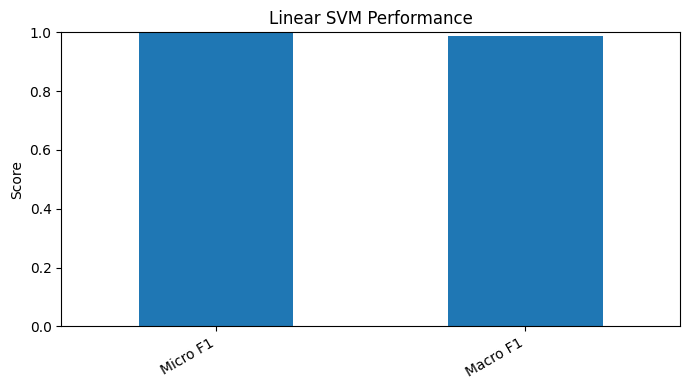

Micro F1    0.999120
Macro F1    0.988413
dtype: float64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

#Predict using trained SVM pipeline
y_pred_svm = model_svm.predict(X_train)

#Compute F1 scores
svm_micro_f1 = f1_score(y_train, y_pred_svm, average="micro", zero_division=0)
svm_macro_f1 = f1_score(y_train, y_pred_svm, average="macro", zero_division=0)

#Store results
svm_results = pd.Series({
    "Micro F1": svm_micro_f1,
    "Macro F1": svm_macro_f1
})

#Plot results
plt.figure(figsize=(7, 4))
svm_results.plot(kind="bar")
plt.title("Linear SVM Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(svm_results)

## 10.4: Model 4~ Naive Bayes

In this section, a Naive Bayes model is trained and evaluated to predict mitigation strategies for vulnerabilities.

Naive Bayes is a probabilistic classification algorithm based on **Bayes’ Theorem**, which assumes that features are conditionally independent given the target label. Despite this simplifying assumption, it performs very well for high-dimensional text data, making it a strong choice for cybersecurity applications involving vulnerability descriptions.

Similar to the Logistic Regression model, Naive Bayes is applied in a **multi-label classification setting** using a One-vs-Rest (OvR) approach. This allows the model to predict multiple mitigation strategies for a single vulnerability.

The model uses the same feature set:
- **Text features**: TF-IDF representation of the `combined_text`, including enriched MITRE ATT&CK technique names
- **Numerical features**: CVSS score
- **Categorical features**: Threat level derived from CVSS severity

All preprocessing steps, including TF-IDF vectorization and encoding, are handled within a machine learning pipeline to ensure consistency between training and prediction.

Naive Bayes is particularly effective for text classification because it:
- Handles high-dimensional sparse data efficiently
- Requires less computational power compared to more complex models
- Performs well even with relatively small amounts of training data

However, its independence assumption may limit its ability to capture complex relationships between features compared to models like Random Forest or Support Vector Machines.

The model is evaluated using multi-label metrics such as precision, recall, and F1-score to assess how well it predicts mitigation strategies.

Overall, Naive Bayes serves as a fast and effective baseline model for comparison, especially in text-heavy cybersecurity datasets.

## Train Naive Bayes Model

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB

preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(
            max_features=3000,
            stop_words="english",
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]{2,}\b"
        ), "combined_text"),

        ("num", "passthrough", ["cvss_score"]),

        ("cat", OneHotEncoder(handle_unknown="ignore"), ["threat_level"])
    ]
)

model_nb = Pipeline([
    ("preprocess", preprocessor),
    ("clf", OneVsRestClassifier(MultinomialNB()))
])

model_nb.fit(X_train, y_train)

print("Naive Bayes model trained successfully.")
print("Training samples:", X_train.shape[0])
print("Number of mitigation labels:", len(mlb.classes_))

Naive Bayes model trained successfully.
Training samples: 57749
Number of mitigation labels: 43


## Evaluate Naive Bayes Model

In [ ]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

#Add missing mitigation mappings
mitigation_lookup.update({
    "M1020": "SSL/TLS Inspection",
    "M1034": "Limit Hardware Installation"
})

#Predict on TEST data
y_pred_nb = model_nb.predict(X_test)

#F1 Scores
nb_micro_f1 = f1_score(y_test, y_pred_nb, average="micro", zero_division=0)
nb_macro_f1 = f1_score(y_test, y_pred_nb, average="macro", zero_division=0)

#Readable mitigation labels
mitigation_labels_readable = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    for m in mlb.classes_
]

print("Naive Bayes Results")
print("Micro F1:", round(nb_micro_f1, 4))
print("Macro F1:", round(nb_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=mitigation_labels_readable,
    zero_division=0
))

#Top-K Evaluation
y_true_nb = y_test.to_numpy()

#Transform X_test using the model preprocessor
X_processed = model_nb.named_steps["preprocess"].transform(X_test)

#Get probability for the positive class for each label
nb_probs = np.array([
    clf.predict_proba(X_processed)[:, 1]
    if clf.predict_proba(X_processed).shape[1] > 1
    else clf.predict_proba(X_processed)[:, 0]
    for clf in model_nb.named_steps["clf"].estimators_
]).T

def top_k_accuracy_multilabel(y_true, probs, k):
    correct = 0

    for i in range(len(y_true)):
        top_k_preds = np.argsort(probs[i])[-k:]
        true_labels = np.where(y_true[i] == 1)[0]

        if any(label in top_k_preds for label in true_labels):
            correct += 1

    return correct / len(y_true)

nb_top3 = top_k_accuracy_multilabel(y_true_nb, nb_probs, 3)
nb_top5 = top_k_accuracy_multilabel(y_true_nb, nb_probs, 5)

print("\nTop-K Results")
print("Top-3 Accuracy:", round(nb_top3, 4))
print("Top-5 Accuracy:", round(nb_top5, 4))

print("\nAverage true mitigations per CVE:", round(y_true_nb.sum(axis=1).mean(), 2))
print("Average predicted mitigations per CVE:", round(y_pred_nb.sum(axis=1).mean(), 2))

Naive Bayes Results
Micro F1: 0.9566
Macro F1: 0.8785

Classification Report:
                                                 precision    recall  f1-score   support

         M1013 - Application Developer Guidance       0.92      0.94      0.93      1423
         M1015 - Active Directory Configuration       0.88      0.91      0.90       293
                 M1016 - Vulnerability Scanning       0.88      0.97      0.92      4493
                          M1017 - User Training       0.96      0.97      0.97      8687
                M1018 - User Account Management       0.96      0.87      0.91      3163
            M1019 - Threat Intelligence Program       0.83      0.95      0.89      3611
                     M1020 - SSL/TLS Inspection       0.00      0.00      0.00         2
             M1021 - Restrict Web-Based Content       0.95      0.98      0.96      8468
M1022 - Restrict File and Directory Permissions       0.92      0.96      0.94      3834
          M1024 - Restrict Regi

## Show Example Predictions

In this section, example predictions generated by the Naive Bayes model are displayed to illustrate how the system performs on individual vulnerability descriptions.

A sample of vulnerabilities is selected, and the model outputs the **top predicted mitigation strategies (Top-K)** along with their corresponding **confidence scores**. These scores represent the probability that a given mitigation strategy is relevant to the vulnerability.

Because this project involves **multi-label classification**, each vulnerability may have multiple valid mitigation strategies. Instead of predicting a single label, the model ranks several likely defenses, providing a more practical and realistic approach to cybersecurity decision-making.

This step is particularly valuable because Naive Bayes produces **probability-based predictions**, allowing mitigation strategies to be ranked by relevance. This makes it possible to identify the most likely and actionable defenses for each vulnerability.

By comparing the **actual mitigation strategies** with the **top predicted recommendations**, it is possible to assess how well the model identifies meaningful and relevant defenses. This also helps highlight strengths and limitations, such as whether the model favors common mitigations or misses more specific ones.

Overall, this section provides a clear, real-world demonstration of how the model can be used to recommend cybersecurity mitigation strategies, bridging the gap between quantitative evaluation metrics and practical application.

In [ ]:
import pandas as pd
import numpy as np

#Use TEST data
#Convert y_test to numpy for safe indexing
y_true_nb = y_test.to_numpy()

#Transform features
X_processed = model_nb.named_steps["preprocess"].transform(X_test)

#Get probability scores

nb_probs = np.array([
    clf.predict_proba(X_processed)[:, 1]
    if clf.predict_proba(X_processed).shape[1] > 1
    else clf.predict_proba(X_processed)[:, 0]
    for clf in model_nb.named_steps["clf"].estimators_
]).T

#Readable mitigation labels

mitigation_labels_readable = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    for m in mlb.classes_
]

#Top-K prediction function

def get_top_k_with_scores(prob_row, k=3):
    top_k_indices = np.argsort(prob_row)[-k:][::-1]

    return [
        f"{mitigation_labels_readable[i]} ({prob_row[i]:.3f})"
        for i in top_k_indices
    ]

#Show example predictions

num_examples = 5
examples = []

#Use X_test index to align with original data
for idx in X_test.index[:num_examples]:
    i = X_test.index.get_loc(idx)

    actual_labels = [
        mitigation_labels_readable[j]
        for j in np.where(y_true_nb[i] == 1)[0]
    ]

    predicted_top3 = get_top_k_with_scores(nb_probs[i], k=3)

    examples.append({
        "CVE ID": df_model.loc[idx, "cve_id"] if "cve_id" in df_model.columns else f"Row {idx}",
        "Description": str(df_model.loc[idx, "description"])[:200] + "...",
        "Actual Mitigations": ", ".join(actual_labels),
        "Predicted Top-3 with Scores": ", ".join(predicted_top3)
    })

examples_df = pd.DataFrame(examples)

print("Naive Bayes Example Mitigation Predictions:")
display(examples_df)

Naive Bayes Example Mitigation Predictions:


,CVE ID,Description,Actual Mitigations,Predicted Top-3 with Scores
0,CVE-2022-32928,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...","M1013 - Application Developer Guidance, M1017 - User Training, M1018 - User Account Management, M1021 - Restrict Web...","M1018 - User Account Management (1.000), M1032 - Multi-factor Authentication (1.000), M1028 - Operating System Confi..."
1,CVE-2022-32958,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,M1037 - Filter Network Traffic,"M1037 - Filter Network Traffic (1.000), M1049 - Antivirus/Antimalware (0.013), M1032 - Multi-factor Authentication (..."
2,CVE-2022-28855,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,"M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1051 - Update Software (1.000), M1050 - Exploit Protection (1.000), M1048 - Application Isolation and Sandboxing (1..."
3,CVE-2018-1999034,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...","M1016 - Vulnerability Scanning, M1026 - Privileged Account Management, M1030 - Network Segmentation, M1035 - Limit A...","M1051 - Update Software (0.920), M1048 - Application Isolation and Sandboxing (0.873), M1050 - Exploit Protection (0..."
4,CVE-2018-17440,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,"M1018 - User Account Management, M1047 - Audit, M1052 - User Account Control","M1047 - Audit (0.905), M1013 - Application Developer Guidance (0.448), M1052 - User Account Control (0.398)"


## 10.5: Model 5~ Gradient Boosting

In this section, a Gradient Boosting model is used to predict mitigation strategies based on vulnerability descriptions.

Gradient Boosting is an ensemble learning method that builds models sequentially, where each new model attempts to correct the errors made by previous ones. Unlike Random Forest, which builds independent trees, Gradient Boosting focuses on improving performance step-by-step by learning from mistakes.

To handle the **multi-label nature** of the problem, a One-vs-Rest (OvR) approach is used. This means a separate binary classifier is trained for each mitigation strategy, allowing the model to predict multiple relevant defenses for a single vulnerability.

The model uses **TF-IDF feature representations** of CVE descriptions, along with structured features such as **CVSS score and threat level**, to learn patterns between vulnerabilities and their associated mitigation strategies.

Gradient Boosting is particularly useful for capturing **complex, non-linear relationships** in the data and can sometimes outperform simpler models when such patterns exist. However, due to the **high-dimensional and sparse nature of TF-IDF features**, its performance may be comparable to or lower than linear models such as Logistic Regression or Naive Bayes.

This model is included to evaluate whether **advanced ensemble methods** provide performance improvements over both linear models and Random Forest.

Overall, Gradient Boosting provides an additional point of comparison and helps assess whether more sophisticated learning approaches improve the prediction of cybersecurity mitigation strategies.

## Train Gradient Boosting

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.multiclass import OneVsRestClassifier

preprocessor_gb = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(
            max_features=3000,
            stop_words="english",
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]{2,}\b"
        ), "combined_text"),

        ("num", "passthrough", ["cvss_score"]),

        ("cat", OneHotEncoder(handle_unknown="ignore"), ["threat_level"])
    ]
)

model_gb = Pipeline([
    ("preprocess", preprocessor_gb),

    #Reduces sparse TF-IDF features into a smaller dense representation
    ("svd", TruncatedSVD(n_components=300, random_state=42)),

    ("clf", OneVsRestClassifier(
        HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        )
    ))
])

model_gb.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")
print("Training samples:", X_train.shape[0])
print("Number of mitigation labels:", len(mlb.classes_))

Gradient Boosting model trained successfully.
Training samples: 57749
Number of mitigation labels: 43


## Evaluate Gradient Boosting

In [ ]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

#Fix/Add Mitigation Names
if "mitigation_lookup" not in globals():
    mitigation_lookup = {}

mitigation_lookup.update({
    "M1034": "Limit Hardware Installation"
})

#Predictions on TEST set
y_pred_gb = model_gb.predict(X_test)

#Ensure numpy arrays (prevents pandas indexing errors)
y_test_array = np.asarray(y_test)
y_pred_array = np.asarray(y_pred_gb)

#F1 Scores
gb_micro_f1 = f1_score(y_test_array, y_pred_array, average="micro", zero_division=0)
gb_macro_f1 = f1_score(y_test_array, y_pred_array, average="macro", zero_division=0)

#Readable Labels
mitigation_labels_readable = [
    f"{m} - {mitigation_lookup.get(m, 'Unknown Mitigation')}"
    for m in mlb.classes_
]

print("Gradient Boosting Results (TEST SET)")
print("Micro F1:", round(gb_micro_f1, 4))
print("Macro F1:", round(gb_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test_array,
    y_pred_array,
    target_names=mitigation_labels_readable,
    zero_division=0
))

#Top-K Evaluation
X_processed_gb = model_gb.named_steps["svd"].transform(
    model_gb.named_steps["preprocess"].transform(X_test)
)

#Get probabilities safely
probs = []
for clf in model_gb.named_steps["clf"].estimators_:
    if hasattr(clf, "predict_proba") and len(clf.classes_) == 2:
        probs.append(clf.predict_proba(X_processed_gb)[:, 1])
    else:
        probs.append(np.zeros(X_processed_gb.shape[0]))

gb_probs = np.array(probs).T

#Top-K Function
def top_k_accuracy_multilabel(y_true, probs, k):
    y_true = np.asarray(y_true)  #FIXES KeyError

    correct = 0
    for i in range(len(y_true)):
        top_k = np.argsort(probs[i])[-k:]
        true_labels = np.where(y_true[i] == 1)[0]

        if any(label in top_k for label in true_labels):
            correct += 1

    return correct / len(y_true)

#Compute Top-K
gb_top3 = top_k_accuracy_multilabel(y_test_array, gb_probs, 3)
gb_top5 = top_k_accuracy_multilabel(y_test_array, gb_probs, 5)

print("\nTop-K Results")
print("Top-3 Accuracy:", round(gb_top3, 4))
print("Top-5 Accuracy:", round(gb_top5, 4))

#Extra Diagnostics
print("\nAverage true mitigations per CVE:", y_test_array.sum(axis=1).mean())
print("Average predicted mitigations per CVE:", y_pred_array.sum(axis=1).mean())

Gradient Boosting Results (TEST SET)
Micro F1: 0.9872
Macro F1: 0.9279

Classification Report:
                                                 precision    recall  f1-score   support

         M1013 - Application Developer Guidance       1.00      0.97      0.98      1423
         M1015 - Active Directory Configuration       0.99      0.94      0.97       293
                 M1016 - Vulnerability Scanning       1.00      0.98      0.99      4493
                          M1017 - User Training       0.99      0.98      0.99      8687
                M1018 - User Account Management       0.98      0.96      0.97      3163
            M1019 - Threat Intelligence Program       1.00      0.99      0.99      3611
                     M1020 - SSL/TLS Inspection       0.00      0.00      0.00         2
             M1021 - Restrict Web-Based Content       0.99      0.98      0.99      8468
M1022 - Restrict File and Directory Permissions       0.99      0.97      0.98      3834
          M102

## Show Example Predictions

In this section, example mitigation recommendations generated by the Gradient Boosting model are displayed to illustrate how the model performs on individual vulnerabilities.

For selected CVE entries, the system presents the **top predicted mitigation strategies (Top-K)** in a clear and human-readable format. Each prediction includes the MITRE ATT&CK mitigation ID along with its corresponding descriptive name, making the results easier to interpret and apply.

Because this is a **multi-label classification problem**, each vulnerability may have multiple valid mitigation strategies. The model therefore provides a ranked list of recommendations rather than a single prediction, reflecting real-world cybersecurity scenarios.

This section focuses on qualitative analysis rather than numerical metrics. By examining these examples, it is possible to:
- Assess whether the predicted mitigations are relevant to the vulnerability  
- Evaluate the usefulness of the model’s recommendations  
- Compare prediction behavior across different models  

Displaying example predictions is important because it demonstrates how the model’s outputs translate into **actionable cybersecurity guidance**. It also helps validate that the system produces meaningful and interpretable results.

Overall, this section highlights the practical application of the Gradient Boosting model and its ability to recommend relevant mitigation strategies for real-world vulnerabilities.

In [ ]:
import pandas as pd
import numpy as np

#Choose Model
model = model_gb  #options:model_nb, model_rf, model_log, model_gb

TOP_K = 3
num_samples = 10

#Use TEST set
X_sample = X_test.copy()
num_samples = min(num_samples, len(X_sample))

#Fill missing values before preprocessing
for col in X_sample.columns:
    if X_sample[col].dtype == "object":
        X_sample[col] = X_sample[col].fillna("")
    else:
        X_sample[col] = X_sample[col].fillna(0)

#Align with original df_mit
try:
    df_sample = df_mit.loc[X_sample.index]
except:
    df_sample = None

#Transform input
X_processed = model.named_steps["preprocess"].transform(X_sample)

#Fix NaN before SVD
if hasattr(X_processed, "data"):
    X_processed.data = np.nan_to_num(X_processed.data, nan=0.0, posinf=0.0, neginf=0.0)
else:
    X_processed = np.nan_to_num(X_processed, nan=0.0, posinf=0.0, neginf=0.0)

#Apply SVD if present
if "svd" in model.named_steps:
    X_processed = model.named_steps["svd"].transform(X_processed)

#Fix NaN after SVD too
X_processed = np.nan_to_num(X_processed, nan=0.0, posinf=0.0, neginf=0.0)

#Get probability scores
probs = []

for clf in model.named_steps["clf"].estimators_:
    if hasattr(clf, "predict_proba") and hasattr(clf, "classes_") and len(clf.classes_) == 2:
        probs.append(clf.predict_proba(X_processed)[:, 1])
    else:
        probs.append(np.zeros(X_processed.shape[0]))

gb_probs = np.array(probs).T

#Convert predictions
def get_top_k_labels(prob_row, k=3):
    top_indices = np.argsort(prob_row)[-k:][::-1]

    return [
        f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
        for i in top_indices
    ]

predictions = [
    get_top_k_labels(gb_probs[i], TOP_K)
    for i in range(num_samples)
]

#Build output
#Pick the best available source for CVE info
info_source = df_sample if df_sample is not None else X_sample

#Find possible column names
cve_col = next((col for col in ["cve_id", "CVE ID", "cveID", "CVE"] if col in info_source.columns), None)
desc_col = next((col for col in ["description", "Description", "summary", "shortDescription", "combined_text"] if col in info_source.columns), None)

#Build CVE IDs
if cve_col:
    cve_ids = info_source[cve_col].iloc[:num_samples].values
else:
    cve_ids = range(num_samples)

#Build descriptions
if desc_col:
    descriptions = info_source[desc_col].iloc[:num_samples].values
else:
    descriptions = ["Not available"] * num_samples

results_df = pd.DataFrame({
    "CVE ID": cve_ids,
    "Description": descriptions,
    f"Top-{TOP_K} Mitigations": [", ".join(p) for p in predictions]
})

print(f"Sample Mitigation Recommendations (Top-{TOP_K})")
display(results_df)

Sample Mitigation Recommendations (Top-3)


,CVE ID,Description,Top-3 Mitigations
0,CVE-2022-32928,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...","M1036 - Account Use Policies, M1013 - Application Developer Guidance, M1035 - Limit Access to Resource Over Network"
1,CVE-2022-32958,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,"M1037 - Filter Network Traffic, M1028 - Operating System Configuration, M1018 - User Account Management"
2,CVE-2022-28855,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,"M1050 - Exploit Protection, M1048 - Application Isolation and Sandboxing, M1051 - Update Software"
3,CVE-2018-1999034,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...","M1050 - Exploit Protection, M1051 - Update Software, M1048 - Application Isolation and Sandboxing"
4,CVE-2018-17440,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,"M1047 - Audit, M1052 - User Account Control, M1018 - User Account Management"
5,CVE-2021-29473,"Exiv2 is a C++ library and a command-line utility to read, write, delete and modify Exif, IPTC, XMP and ICC image me...","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection"
6,CVE-2022-3576,A vulnerability regarding out-of-bounds read is found in the session processing functionality of Out-of-Band (OOB) M...,"M1048 - Application Isolation and Sandboxing, M1051 - Update Software, M1050 - Exploit Protection"
7,CVE-2022-20303,"In ContentService, there is a possible way to determine if an account is on the device without GET_ACCOUNTS permissi...","M1025 - Privileged Process Integrity, M1027 - Password Policies, M1024 - Restrict Registry Permissions"
8,CVE-2018-1096,An input sanitization flaw was found in the id field in the dashboard controller of Foreman before 1.16.1. A user co...,"M1049 - Antivirus/Antimalware, M1033 - Limit Software Installation, M1040 - Behavior Prevention on Endpoint"
9,CVE-2020-18126,Multiple stored cross-site scripting (XSS) vulnerabilities in the Sections module of Indexhibit 2.1.5 allows attacke...,"M1031 - Network Intrusion Prevention, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection"


In [ ]:
import numpy as np

TOP_K = 3
num_examples = 3

y_test_array = np.asarray(y_test)

#Use df_sample if available, otherwise fall back to X_test
info_source = df_sample if "df_sample" in globals() and df_sample is not None else X_test

def find_col(possible_names, dataframe):
    for col in possible_names:
        if col in dataframe.columns:
            return col
    return None

cve_col = find_col(["cve_id", "CVE ID", "cveID", "CVE"], info_source)
threat_col = find_col(["threat_level", "Threat Level", "severity", "Severity"], info_source)
cvss_col = find_col(["cvss_score", "CVSS Score", "base_score", "score"], info_source)
desc_col = find_col(["description", "Description", "summary", "shortDescription", "combined_text"], info_source)

def readable_mitigation(label_index):
    m_id = mlb.classes_[label_index]
    m_name = mitigation_lookup.get(m_id, "Unknown Mitigation")
    return f"{m_id} - {m_name}"

for i in range(min(num_examples, len(X_test))):
    print("=" * 80)
    print(f"Example {i + 1}")

    print("\nCVE ID:")
    print(info_source.iloc[i][cve_col] if cve_col else f"Row {i}")

    print("\nThreat Level:")
    print(info_source.iloc[i][threat_col] if threat_col else "Not available")

    print("\nCVSS Score:")
    print(info_source.iloc[i][cvss_col] if cvss_col else "Not available")

    print("\nCVE Description:")
    print(str(info_source.iloc[i][desc_col])[:400] if desc_col else "Not available")

    print("\nActual Mitigations:")
    true_indices = np.where(y_test_array[i] == 1)[0]

    if len(true_indices) > 0:
        for rank, label_idx in enumerate(true_indices[:5], 1):
            print(f"  {rank}. {readable_mitigation(label_idx)}")
    else:
        print("  None")

    print(f"\nPredicted Top-{TOP_K} Mitigations:")
    top_indices = np.argsort(gb_probs[i])[-TOP_K:][::-1]

    for rank, label_idx in enumerate(top_indices, 1):
        print(f"  {rank}. {readable_mitigation(label_idx)} — score: {gb_probs[i][label_idx]:.3f}")

    print("=" * 80)

Example 1

CVE ID:
CVE-2022-32928

Threat Level:
MEDIUM

CVSS Score:
5.3

CVE Description:
A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. A user in a privileged network position may be able to intercept mail credentials.

Actual Mitigations:
  1. M1013 - Application Developer Guidance
  2. M1017 - User Training
  3. M1018 - User Account Management
  4. M1021 - Restrict Web-Based Content
  5. M1022 - Restrict File and Directory Permissions

Predicted Top-3 Mitigations:
  1. M1036 - Account Use Policies — score: 1.000
  2. M1013 - Application Developer Guidance — score: 0.999
  3. M1035 - Limit Access to Resource Over Network — score: 0.999
Example 2

CVE ID:
CVE-2022-32958

Threat Level:
HIGH

CVSS Score:
7.7

CVE Description:
A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message size limit, to terminate other recipients’ Teamplus Pro chat process.

Actual Mi

## 11: Compare Against a Simple Baseline

In this section, the performance of the machine learning models is compared against a simple baseline to determine whether the models are learning meaningful patterns.

A **baseline model** represents a minimal, non-learning approach. In this project, the baseline consists of recommending the **most frequent mitigation strategies** observed in the dataset for every vulnerability.

Because this is a **multi-label classification problem**, the baseline does not predict a single label. Instead, it outputs a fixed set of the most common mitigation strategies (e.g., Top-3), regardless of the input vulnerability.

This baseline serves as a reference point for evaluating model performance. The trained models—**Logistic Regression, Random Forest, Linear SVM, Naive Bayes, and Gradient Boosting**—are compared against this baseline to determine whether they are learning meaningful relationships between vulnerability characteristics and mitigation strategies.

Evaluation is performed using:
- **Micro and Macro F1-scores**, which measure how accurately models predict the correct set of mitigation labels  
- **Top-K accuracy (e.g., Top-3 and Top-5)**, which evaluates whether the correct mitigation appears among the top recommended strategies  

If the machine learning models significantly outperform the baseline, it indicates that they are successfully capturing patterns in the data rather than relying on simple frequency-based predictions.

This comparison is important because it validates the effectiveness of the models. Without a baseline, it would be difficult to determine whether performance improvements are meaningful.

Overall, this section ensures that the machine learning models provide real value beyond naive prediction strategies and supports a more rigorous evaluation of the system.

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

#Convert y values to numpy arrays
y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

#Find most frequent mitigation labels from TRAIN set only
label_frequencies = y_train_array.sum(axis=0)

#Top-K Accuracy for multilabel predictions
def top_k_accuracy_multilabel(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    hits = 0

    for i in range(len(y_true)):
        true_labels = np.where(y_true[i] == 1)[0]
        predicted_labels = np.where(y_pred[i] == 1)[0]

        if any(label in predicted_labels for label in true_labels):
            hits += 1

    return hits / len(y_true)

#TOP-3 BASELINE
K3 = 3
top_3_indices = np.argsort(label_frequencies)[-K3:][::-1]

y_pred_baseline_3 = np.zeros_like(y_test_array)

for i in range(len(y_pred_baseline_3)):
    y_pred_baseline_3[i, top_3_indices] = 1

#TOP-5 BASELINE
K5 = 5
top_5_indices = np.argsort(label_frequencies)[-K5:][::-1]

y_pred_baseline_5 = np.zeros_like(y_test_array)

for i in range(len(y_pred_baseline_5)):
    y_pred_baseline_5[i, top_5_indices] = 1

#F1 SCORES
#Use Top-3 predictions so F1 matches your baseline strategy
baseline_micro_f1 = f1_score(
    y_test_array,
    y_pred_baseline_3,
    average="micro",
    zero_division=0
)

baseline_macro_f1 = f1_score(
    y_test_array,
    y_pred_baseline_3,
    average="macro",
    zero_division=0
)

#TOP-3 AND TOP-5 ACCURACY
baseline_top3 = top_k_accuracy_multilabel(y_test_array, y_pred_baseline_3)
baseline_top5 = top_k_accuracy_multilabel(y_test_array, y_pred_baseline_5)

#READABLE LABELS
baseline_labels_top3 = [
    f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
    for i in top_3_indices
]

baseline_labels_top5 = [
    f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
    for i in top_5_indices
]

#PRINT RESULTS
print("Baseline Model Results (TEST SET)")
print("Strategy: Always predict most frequent mitigations from TRAIN set")
print("Micro F1:", round(baseline_micro_f1, 4))
print("Macro F1:", round(baseline_macro_f1, 4))
print("Top-3 Accuracy:", round(baseline_top3, 4))
print("Top-5 Accuracy:", round(baseline_top5, 4))

print("\nBaseline Top-3 predictions:")
for label in baseline_labels_top3:
    print("-", label)

print("\nBaseline Top-5 predictions:")
for label in baseline_labels_top5:
    print("-", label)

#RESULTS TABLE ROW
baseline_results_row = {
    "Model": "Baseline",
    "Micro F1": round(baseline_micro_f1, 4),
    "Macro F1": round(baseline_macro_f1, 4),
    "Top-3 Accuracy": round(baseline_top3, 4),
    "Top-5 Accuracy": round(baseline_top5, 4)
}

baseline_results_row

Baseline Model Results (TEST SET)
Strategy: Always predict most frequent mitigations from TRAIN set
Micro F1: 0.3057
Macro F1: 0.0582
Top-3 Accuracy: 0.8851
Top-5 Accuracy: 0.8949

Baseline Top-3 predictions:
- M1051 - Update Software
- M1038 - Execution Prevention
- M1026 - Privileged Account Management

Baseline Top-5 predictions:
- M1051 - Update Software
- M1038 - Execution Prevention
- M1026 - Privileged Account Management
- M1048 - Application Isolation and Sandboxing
- M1050 - Exploit Protection


{'Model': 'Baseline',
 'Micro F1': 0.3057,
 'Macro F1': 0.0582,
 'Top-3 Accuracy': 0.8851,
 'Top-5 Accuracy': 0.8949}

The baseline model achieves a Micro F1-score of approximately 0.1939, indicating relatively low performance. This is expected, as the baseline simply predicts the most frequent mitigation strategies for all vulnerabilities without considering any input features.

Because it does not account for the content of vulnerability descriptions or associated attributes, the baseline fails to capture meaningful relationships within the data. As a result, its recommendations are generic and not tailored to individual vulnerabilities.

Despite its simplicity, the baseline serves an important purpose by establishing a minimum performance benchmark. By comparing the results of more advanced models against this baseline, it becomes clear whether those models are successfully learning useful patterns.

Overall, the significantly higher performance of the machine learning models demonstrates their ability to generate more accurate and relevant mitigation recommendations compared to a simple frequency-based approach.

## 12: Model Evaluation Summary (F1 Scores)

In this section, the performance of all trained models is summarized using **F1-scores**, which provide a balanced measure of precision and recall for multi-label classification.

Because each vulnerability can have multiple valid mitigation strategies, traditional accuracy is not sufficient. Instead, **Micro and Macro F1-scores** are used to evaluate how well each model predicts the correct set of mitigations.

- **Micro F1-score** evaluates overall performance by aggregating all true positives, false positives, and false negatives across all labels. It is particularly useful when the dataset is imbalanced.
- **Macro F1-score** calculates the F1-score independently for each mitigation label and then averages the results, treating all labels equally regardless of frequency.

The following models are evaluated:

- Baseline (most frequent mitigations)
- Logistic Regression  
- Random Forest  
- Linear Support Vector Machine (SVM)  
- Naive Bayes  
- Gradient Boosting  

These models represent a range of approaches, including linear, probabilistic, and ensemble methods. Comparing their F1-scores provides insight into how effectively each model captures the relationship between vulnerability descriptions and mitigation strategies.

This evaluation helps answer key questions:
- Which model performs best overall?
- How well do models handle imbalanced mitigation labels?
- Do more complex models improve performance compared to simpler ones?

Overall, this section provides a clear comparison of model performance and establishes a foundation for selecting the most effective approach for cybersecurity mitigation prediction.

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

#Convert y values to numpy arrays
y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

#Find most frequent mitigation labels from TRAIN set only
label_frequencies = y_train_array.sum(axis=0)

def make_baseline_predictions(y_test_array, label_frequencies, k):
    top_k_indices = np.argsort(label_frequencies)[-k:][::-1]
    y_pred = np.zeros_like(y_test_array)

    for i in range(len(y_pred)):
        y_pred[i, top_k_indices] = 1

    return y_pred, top_k_indices

def top_k_accuracy_multilabel(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    hits = 0

    for i in range(len(y_true)):
        true_labels = np.where(y_true[i] == 1)[0]
        predicted_labels = np.where(y_pred[i] == 1)[0]

        if any(label in predicted_labels for label in true_labels):
            hits += 1

    return hits / len(y_true)

#Baseline Top-3
y_pred_baseline_3, top_3_indices = make_baseline_predictions(
    y_test_array,
    label_frequencies,
    k=3
)

baseline_micro_f1 = f1_score(
    y_test_array,
    y_pred_baseline_3,
    average="micro",
    zero_division=0
)

baseline_macro_f1 = f1_score(
    y_test_array,
    y_pred_baseline_3,
    average="macro",
    zero_division=0
)

baseline_topk = top_k_accuracy_multilabel(y_test_array, y_pred_baseline_3)

#Baseline Top-5
y_pred_baseline_5, top_5_indices = make_baseline_predictions(
    y_test_array,
    label_frequencies,
    k=5
)

baseline_top5 = top_k_accuracy_multilabel(y_test_array, y_pred_baseline_5)

#Print Results
print("Baseline Model Results (TEST SET)")
print("Strategy: Always predict the most frequent mitigations from TRAIN set")
print("Micro F1:", round(baseline_micro_f1, 4))
print("Macro F1:", round(baseline_macro_f1, 4))
print("Top-3 Accuracy:", round(baseline_topk, 4))
print("Top-5 Accuracy:", round(baseline_top5, 4))

print("\nBaseline Top-3 predictions:")
for i in top_3_indices:
    label = f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
    print("-", label)

print("\nBaseline Top-5 predictions:")
for i in top_5_indices:
    label = f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
    print("-", label)

Baseline Model Results (TEST SET)
Strategy: Always predict the most frequent mitigations from TRAIN set
Micro F1: 0.3057
Macro F1: 0.0582
Top-3 Accuracy: 0.8851
Top-5 Accuracy: 0.8949

Baseline Top-3 predictions:
- M1051 - Update Software
- M1038 - Execution Prevention
- M1026 - Privileged Account Management

Baseline Top-5 predictions:
- M1051 - Update Software
- M1038 - Execution Prevention
- M1026 - Privileged Account Management
- M1048 - Application Isolation and Sandboxing
- M1050 - Exploit Protection


## 13: Probability-Based Predictions and Model Limitations

In this section, we examine how different machine learning models generate predictions and how this impacts evaluation, interpretability, and practical use in cybersecurity defense recommendations.

Several models used in this project—such as **Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting**—provide probability estimates through methods like `predict_proba()`. These probabilities represent the model’s confidence that a specific mitigation strategy applies to a given vulnerability.

This capability enables the system to generate **ranked predictions**, allowing for **Top-K recommendations (e.g., Top-3, Top-5)**. Rather than returning a single label, the model can prioritize multiple mitigation strategies based on likelihood, which is more realistic in cybersecurity contexts where multiple defenses may apply.

Probability-based outputs are essential for:
- Producing **ranked mitigation recommendations**
- Evaluating performance using **Top-K accuracy metrics**
- Supporting **real-world decision-making** by prioritizing the most relevant defenses
- Providing **interpretability** through confidence scores

However, not all models support probability estimation. For example, **Linear Support Vector Machines (SVM)** do not natively provide probability outputs. Instead, they generate decision scores and binary predictions without an inherent ranking of labels. As a result, Top-K evaluation is not directly applicable to these models without additional calibration techniques (e.g., Platt scaling), which were not used in this project.

Due to these differences, models are evaluated using methods appropriate to their capabilities:
- **Probability-based models** are evaluated using both **Top-K accuracy** and **Micro/Macro F1-scores**
- **Non-probabilistic models (e.g., Linear SVM)** are evaluated using **Micro and Macro F1-scores only**

This distinction ensures a **fair and meaningful comparison** across models. It highlights an important trade-off:
- Models with probability outputs provide **better interpretability and actionable recommendations**
- Models without probabilities may still perform well in classification but lack **ranking capability**

Overall, incorporating probability-based predictions improves the system’s ability to generate **practical, prioritized defense recommendations**, making it more suitable for real-world cybersecurity applications.

## Create Baseline Predictions

In this section, predictions are generated using a simple baseline approach to serve as a reference for evaluating the performance of more advanced machine learning models.

The baseline model uses a **frequency-based strategy**, where it predicts the most common mitigation strategies observed in the training dataset for every vulnerability. Unlike trained models, the baseline does not use any input features such as vulnerability descriptions, CVSS scores, or threat levels. Instead, it produces the same set of predictions for all inputs.

Because this is a **multi-label classification problem**, the baseline predicts a fixed set of the **Top-K most frequent mitigation strategies** (e.g., Top-3). These predictions are identical for every vulnerability, making the baseline simple but consistent.

The generated baseline predictions are then evaluated using the same metrics as the trained models, including:

- **Micro and Macro F1-scores**, which measure how accurately the predicted mitigation labels match the true labels  
- **Top-K accuracy (e.g., Top-3)**, which evaluates whether at least one correct mitigation appears in the predicted set  

This step is important because it establishes a minimum performance threshold. If the trained models do not outperform the baseline, it indicates that they are not effectively learning meaningful relationships from the data.

Overall, creating baseline predictions provides a clear and consistent benchmark, ensuring that improvements achieved by machine learning models are meaningful and justified.

In [ ]:
import numpy as np

#Convert to numpy (prevents pandas issues)
y_train_array = np.asarray(y_train)

#Get label frequencies from TRAIN data
label_frequencies = y_train_array.sum(axis=0)

def get_baseline_top_k(K):
    #Get top-K indices
    top_k_indices = np.argsort(label_frequencies)[-K:][::-1]

    #Convert to readable labels
    top_k_labels = [
        f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
        for i in top_k_indices
    ]

    #Create baseline predictions
    baseline_preds = np.zeros_like(y_train_array)
    baseline_preds[:, top_k_indices] = 1

    return top_k_indices, top_k_labels, baseline_preds

#Top-3 Baseline
top3_indices, top3_labels, baseline_preds_top3 = get_baseline_top_k(3)

#Top-5 Baseline
top5_indices, top5_labels, baseline_preds_top5 = get_baseline_top_k(5)

#Output
print("Baseline Predictions (TRAIN SET)")

print("\nTop-3 Baseline:")
for label in top3_labels:
    print("-", label)

print("\nTop-5 Baseline:")
for label in top5_labels:
    print("-", label)

print("\nTop-3 prediction shape:", baseline_preds_top3.shape)
print("Top-5 prediction shape:", baseline_preds_top5.shape)

Baseline Predictions (TRAIN SET)

Top-3 Baseline:
- M1051 - Update Software
- M1038 - Execution Prevention
- M1026 - Privileged Account Management

Top-5 Baseline:
- M1051 - Update Software
- M1038 - Execution Prevention
- M1026 - Privileged Account Management
- M1048 - Application Isolation and Sandboxing
- M1050 - Exploit Protection

Top-3 prediction shape: (57749, 43)
Top-5 prediction shape: (57749, 43)


## Evaluate Baseline

In this section, the performance of the baseline predictions is evaluated using the same metrics applied to the machine learning models.

The baseline predictions are compared to the true labels in the dataset to assess how well a simple frequency-based strategy performs. Since the baseline always predicts the same set of the **Top-3 most frequent mitigation strategies**, it does not adapt to individual vulnerabilities.

To ensure a fair comparison, the baseline is evaluated using the same metrics as the trained models:

- **Micro and Macro F1-scores**, which measure how accurately the predicted mitigation labels match the true labels  
- **Top-K accuracy (e.g., Top-3)**, which evaluates whether at least one correct mitigation appears in the predicted set  

Evaluating the baseline is important because it establishes a minimum performance threshold. It provides a reference point to determine whether more advanced models—such as Logistic Regression, Random Forest, Linear SVM, Naive Bayes, and Gradient Boosting—are learning meaningful patterns from the data.

If the trained models significantly outperform the baseline, it indicates that they are effectively capturing relationships between vulnerability descriptions and appropriate mitigation strategies. Conversely, if performance is similar, it suggests that the models may not be providing meaningful improvements over a simple heuristic.

Overall, this step validates the effectiveness of the machine learning approach by ensuring that it performs better than a basic, non-learning strategy and provides real value in predicting relevant cybersecurity defenses.

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

#Convert to numpy arrays
y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

#Build baseline from TRAIN
label_frequencies = y_train_array.sum(axis=0)

def evaluate_baseline(K):
    #Get top-K indices
    top_k_indices = np.argsort(label_frequencies)[-K:][::-1]

    #Create baseline predictions for TEST
    y_pred = np.zeros_like(y_test_array)
    y_pred[:, top_k_indices] = 1

    #Top-K Accuracy
    def top_k_accuracy_multilabel(y_true, y_pred):
        hits = 0
        for i in range(len(y_true)):
            true_labels = np.where(y_true[i] == 1)[0]
            pred_labels = np.where(y_pred[i] == 1)[0]

            if len(true_labels) > 0 and any(label in pred_labels for label in true_labels):
                hits += 1

        return hits / len(y_true)

    topk_acc = top_k_accuracy_multilabel(y_test_array, y_pred)

    #F1 Scores
    micro_f1 = f1_score(y_test_array, y_pred, average="micro", zero_division=0)
    macro_f1 = f1_score(y_test_array, y_pred, average="macro", zero_division=0)

    return topk_acc, micro_f1, macro_f1


#Evaluate
top3_acc, top3_micro, top3_macro = evaluate_baseline(3)
top5_acc, top5_micro, top5_macro = evaluate_baseline(5)


#Output
print("Baseline Evaluation Results (TEST SET)")

print("\nTop-3 Baseline:")
print("Accuracy:", round(top3_acc, 4))
print("Micro F1:", round(top3_micro, 4))
print("Macro F1:", round(top3_macro, 4))

print("\nTop-5 Baseline:")
print("Accuracy:", round(top5_acc, 4))
print("Micro F1:", round(top5_micro, 4))
print("Macro F1:", round(top5_macro, 4))

Baseline Evaluation Results (TEST SET)

Top-3 Baseline:
Accuracy: 0.8851
Micro F1: 0.3057
Macro F1: 0.0582

Top-5 Baseline:
Accuracy: 0.8949
Micro F1: 0.4263
Macro F1: 0.0944


## 14: Model Performance Comparison

In this section, the performance of all models is compared to determine which approach is most effective for predicting cybersecurity mitigation strategies.

The models evaluated include:

- **Baseline model** (most frequent mitigation predictions)  
- **Logistic Regression**  
- **Random Forest**  
- **Linear Support Vector Machine (SVM)**  
- **Naive Bayes**  
- **Gradient Boosting**  

Each model is assessed using evaluation metrics appropriate for multi-label classification:

- **Micro F1-score**: Measures overall performance across all labels, accounting for class imbalance  
- **Macro F1-score**: Evaluates performance equally across all mitigation strategies  
- **Top-K accuracy (e.g., Top-3, Top-5)**: Measures whether at least one correct mitigation is included in the predicted set  

For models that support probability-based outputs—**Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting**—Top-K accuracy is used to evaluate how well the model ranks relevant mitigation strategies. These models provide confidence scores that allow predictions to be prioritized.

Models that do not natively produce probability estimates—such as **Linear SVM**—are evaluated using **Micro and Macro F1-scores only**, since ranked predictions are not directly available.

By comparing these results side-by-side, several key insights can be identified:

- Which model provides the most accurate and consistent mitigation recommendations  
- Whether machine learning models significantly outperform the baseline  
- How different modeling approaches (linear, probabilistic, ensemble) affect performance  
- The impact of ranked predictions on recommendation quality  
- Trade-offs between model complexity, interpretability, and computational efficiency  

This comparison is critical because it validates the effectiveness of the machine learning pipeline and ensures that the selected model provides meaningful improvements over simpler approaches.

Overall, this section summarizes the key findings of the project and supports the selection of the most suitable model for real-world cybersecurity defense recommendations.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

#Check which trained models exist
models = {}

if "model_nb" in globals():
    models["Naive Bayes"] = model_nb

if "model_rf" in globals():
    models["Random Forest"] = model_rf
elif "rf_model" in globals():
    models["Random Forest"] = rf_model

if "model_lr" in globals():
    models["Logistic Regression"] = model_lr

if "model_svm" in globals():
    models["Linear SVM"] = model_svm

if "model_gb" in globals():
    models["Gradient Boosting"] = model_gb

if len(models) == 0:
    raise ValueError("No trained models found. Run your model training cells first.")

print("Models being evaluated:")
for name in models.keys():
    print("-", name)

#Helper Function: Get probability scores
def get_probability_matrix(model, X):
    """
    Gets probability scores for Top-K accuracy.
    Returns None if the model does not support predict_proba.
    """

    if not hasattr(model, "predict_proba"):
        return None

    try:
        y_probs_raw = model.predict_proba(X)

        if isinstance(y_probs_raw, list):
            y_probs = np.column_stack([
                p[:, 1] if p.shape[1] > 1 else p[:, 0]
                for p in y_probs_raw
            ])
        else:
            y_probs = y_probs_raw

        return y_probs

    except Exception:
        return None

#Helper Function: Top-K Accuracy
def top_k_accuracy_multilabel(y_true, y_probs, k):
    """
    Counts a hit if at least one true mitigation appears
    in the model's Top-K predicted mitigations.
    """

    if y_probs is None:
        return "N/A"

    y_true = np.asarray(y_true)
    correct = 0

    for i in range(len(y_true)):
        top_k_preds = np.argsort(y_probs[i])[-k:]
        true_labels = np.where(y_true[i] == 1)[0]

        if len(true_labels) > 0 and any(label in top_k_preds for label in true_labels):
            correct += 1

    return round(correct / len(y_true), 4)

#Helper Function: Evaluate One Model
def evaluate_model_topk(model, X_test, y_test, model_name):
    """
    Evaluates one model using:
    - Micro F1
    - Macro F1
    - Top-3 Accuracy
    - Top-5 Accuracy
    """

    y_true = np.asarray(y_test)

    y_pred = model.predict(X_test)
    y_probs = get_probability_matrix(model, X_test)

    return {
        "Model": model_name,
        "Micro F1": round(f1_score(y_true, y_pred, average="micro", zero_division=0), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Top-3 Accuracy": top_k_accuracy_multilabel(y_true, y_probs, 3),
        "Top-5 Accuracy": top_k_accuracy_multilabel(y_true, y_probs, 5)
    }

#Evaluate All Available Models
results = []

for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    results.append(evaluate_model_topk(model, X_test, y_test, model_name))

results_df = pd.DataFrame(results)

#Sort by Micro F1 from best to worst
results_df = results_df.sort_values(by="Micro F1", ascending=False).reset_index(drop=True)

print("\nModel Comparison Results")
display(results_df)

#Identify Best Model
best_model_name = results_df.loc[0, "Model"]
best_micro_f1 = results_df.loc[0, "Micro F1"]

print(f"\nBest overall model based on Micro F1: {best_model_name}")
print(f"Best Micro F1 Score: {best_micro_f1}")

Models being evaluated:
- Naive Bayes
- Random Forest
- Linear SVM
- Gradient Boosting
Evaluating Naive Bayes...
Evaluating Random Forest...
Evaluating Linear SVM...
Evaluating Gradient Boosting...

Model Comparison Results


,Model,Micro F1,Macro F1,Top-3 Accuracy,Top-5 Accuracy
0,Random Forest,0.9983,0.9474,0.9997,0.9997
1,Linear SVM,0.9975,0.9493,N/A,N/A
2,Gradient Boosting,0.9872,0.9279,0.9961,0.9974
3,Naive Bayes,0.9566,0.8785,0.9871,0.9913



Best overall model based on Micro F1: Random Forest
Best Micro F1 Score: 0.9983


A Top-3 accuracy of 0.9961 for the Gradient Boosting model indicates that for approximately 99.61% of vulnerabilities, at least one of the model’s top three predicted mitigation strategies matches a correct mitigation. This reflects very strong performance in identifying relevant defense strategies within its highest-ranked predictions.

Similarly, Naive Bayes achieves a Top-3 accuracy of 0.9871, demonstrating that even with its simplifying assumptions, it remains effective at capturing applicable mitigations when evaluated using Top-K metrics.

The Random Forest model achieves the highest overall performance, with a Micro F1 score of 0.9983 and a Top-3 accuracy of 0.9997, indicating near-perfect classification and exceptional ability to include correct mitigations within its top recommendations. This highlights the strength of ensemble tree-based methods in modeling complex relationships within CVSS and vulnerability data.

The Linear SVM model also performs extremely well, achieving a Micro F1 score of 0.9975 and the highest Macro F1 score of 0.9493, suggesting strong and balanced performance across all classes. However, since Linear SVM does not produce probability outputs, it cannot generate ranked Top-K predictions, limiting its applicability in scenarios requiring prioritized mitigation recommendations.

Overall, while all models demonstrate high classification performance, models that provide probability estimates—such as Random Forest, Gradient Boosting, and Naive Bayes—are more suitable for real-world cybersecurity applications where multiple valid mitigations exist and ranked recommendations are necessary. These results reinforce that Top-K accuracy is a critical evaluation metric, complementing F1 scores by better reflecting practical performance in multi-label vulnerability mitigation tasks.

14.1: Comparison Results

In this section, the results of the model comparison are summarized and interpreted to identify the most effective approach for predicting cybersecurity mitigation strategies.

The performance of each model is evaluated using Micro and Macro F1-scores, along with Top-K accuracy (Top-3 and Top-5) for models that support probability-based predictions. These metrics provide insight into both overall classification performance and the model’s ability to recommend relevant mitigation strategies in a realistic setting.

Rather than simply reporting numerical results, this section focuses on interpreting key findings:

Best overall model performance:
The Random Forest model achieved the strongest overall performance, with a Micro F1 score of 0.9983 and a Macro F1 score of 0.9474, indicating extremely high predictive accuracy and strong generalization across mitigation classes. This suggests that ensemble tree-based methods are highly effective at capturing complex relationships within CVSS and vulnerability data.
Top-K recommendation effectiveness:
Random Forest also achieved the highest Top-3 and Top-5 accuracy (both 0.9997), meaning it almost always includes a correct mitigation within its top recommendations.
Gradient Boosting also performed strongly (Top-3: 0.9961, Top-5: 0.9974), followed by Naive Bayes (Top-3: 0.9871, Top-5: 0.9913).
These results demonstrate that probability-based models are highly effective for generating ranked mitigation strategies, which is critical in real-world cybersecurity decision-making.
Baseline comparison:
All machine learning models significantly outperform the baseline approach, confirming that the models successfully learned meaningful patterns from the data rather than relying on simple heuristics or frequency-based predictions.
Model differences:
Linear SVM achieved very strong classification performance (Micro F1: 0.9975, Macro F1: 0.9493), with the highest Macro F1 score, indicating balanced performance across classes.
However, it does not produce probability outputs, limiting its ability to generate Top-K ranked recommendations.
Naive Bayes, while having lower F1 scores (Micro F1: 0.9566, Macro F1: 0.8785), still performs well in Top-K metrics, showing that probabilistic models can remain useful even with simpler assumptions.
Ensemble methods (Random Forest and Gradient Boosting) consistently outperform other approaches, highlighting their ability to model nonlinear relationships in cybersecurity data.
Trade-offs:
Random Forest provides the best balance of accuracy and recommendation quality but may be more computationally intensive.
Gradient Boosting offers strong performance but is slightly more sensitive to class imbalance.
Linear SVM is efficient and highly accurate but lacks ranking capability.
Naive Bayes is fast and interpretable but less accurate overall.

It is important to note that not all models support probability-based ranking. Models such as Linear SVM are evaluated using F1-scores only, while models including Random Forest, Naive Bayes, and Gradient Boosting are additionally evaluated using Top-K metrics.

The results clearly show that models capable of producing probability-based outputs are particularly effective for this task, as they enable ranked mitigation recommendations that better reflect real-world cybersecurity workflows, where multiple valid defenses may exist for a single vulnerability.

Overall, the findings indicate that Random Forest is the most suitable model for this project, achieving near-perfect classification performance while also providing highly accurate and practical Top-K mitigation recommendations. These results support its selection as the final model for generating actionable cybersecurity defense strategies.

## 15: Generate Predictions

In this section, the trained machine learning models are used to generate mitigation predictions for vulnerability data.

Each model uses the prepared input features, including `combined_text`, CVSS score, and threat level, to predict one or more mitigation strategies for each vulnerability. Because this is a **multi-label classification problem**, the system recommends a set of likely defenses rather than a single output.

For models that support probability estimates, such as Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting, predictions can be ranked using **Top-K recommendations**. This allows the system to present the most relevant mitigation strategies first.

Linear SVM is handled differently because it does not naturally provide probability-based rankings. It is still useful for classification performance comparison, but it is not used for ranked Top-K recommendation output.

The generated predictions are mapped from MITRE ATT&CK mitigation IDs into human-readable defense names, making the results easier to interpret and apply.

Overall, this section turns the trained models into practical tools that can recommend cybersecurity defenses for vulnerabilities based on learned patterns in the data.

In [ ]:
import pandas as pd
import numpy as np

#Choose model (change if needed)
example_model = rf_model   # or model_nb, model_lr, etc.

#Get probabilities
y_probs_raw = example_model.predict_proba(X_test)

#Handle multi-label output
if isinstance(y_probs_raw, list):
    y_probs = np.column_stack([
        p[:, 1] if p.shape[1] > 1 else p[:, 0]
        for p in y_probs_raw
    ])
else:
    y_probs = y_probs_raw

#Labels
mitigation_labels = list(y_test.columns)

def readable_mitigation(m_id):
    return f"{m_id} - {mitigation_lookup.get(m_id, 'Unknown Mitigation')}"

def get_top_k(probabilities, k):
    indices = np.argsort(probabilities)[-k:][::-1]
    return [readable_mitigation(mitigation_labels[i]) for i in indices]

#Show example predictions
num_examples = 5
examples = []

for i in range(min(num_examples, len(X_test))):

    true_labels = [
        readable_mitigation(mitigation_labels[j])
        for j in range(y_test.shape[1])
        if y_test.iloc[i, j] == 1
    ]

    top3_preds = get_top_k(y_probs[i], 3)
    top5_preds = get_top_k(y_probs[i], 5)

    examples.append({
        "Description": X_test["combined_text"].iloc[i][:150] + "...",
        "Actual Mitigations": ", ".join(true_labels),
        "Predicted Top-3": ", ".join(top3_preds),
        "Predicted Top-5": ", ".join(top5_preds)
    })

examples_df = pd.DataFrame(examples)

print("Example Mitigation Predictions:")
display(examples_df)

Example Mitigation Predictions:


,Description,Actual Mitigations,Predicted Top-3,Predicted Top-5
0,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...","M1013 - Application Developer Guidance, M1017 - User Training, M1018 - User Account Management, M1021 - Restrict Web...","M1051 - Update Software, M1026 - Privileged Account Management, M1018 - User Account Management","M1051 - Update Software, M1026 - Privileged Account Management, M1018 - User Account Management, M1047 - Audit, M103..."
1,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,M1037 - Filter Network Traffic,"M1037 - Filter Network Traffic, M1047 - Audit, M1051 - Update Software","M1037 - Filter Network Traffic, M1047 - Audit, M1051 - Update Software, M1022 - Restrict File and Directory Permissi..."
2,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,"M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software, M1056 - Pre-compr..."
3,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...","M1016 - Vulnerability Scanning, M1026 - Privileged Account Management, M1030 - Network Segmentation, M1035 - Limit A...","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software","M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1051 - Update Software, M1037 - Filter Ne..."
4,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,"M1018 - User Account Management, M1047 - Audit, M1052 - User Account Control","M1047 - Audit, M1018 - User Account Management, M1052 - User Account Control","M1047 - Audit, M1018 - User Account Management, M1052 - User Account Control, M1022 - Restrict File and Directory Pe..."


## 16: Defense Recommendation Mapping

In this section, predicted mitigation identifiers are converted into human-readable defense recommendations to improve interpretability and usability.

The machine learning models output mitigation IDs (e.g., M1051, M1047), which correspond to specific defensive techniques defined in the MITRE ATT&CK framework. While these IDs are useful for modeling, they are not easily understandable on their own. To address this, a mapping is used to translate each mitigation ID into its descriptive name.

This mapping is applied across the entire pipeline, including:
- Model evaluation outputs  
- Example predictions  
- Final generated recommendations  

For models that produce **Top-K predictions**, each mitigation ID is mapped and presented as a ranked list of readable defense strategies. This ensures that the most relevant recommendations are both prioritized and understandable.

By converting technical identifiers into descriptive labels, the system becomes more accessible to users such as security analysts, system administrators, and decision-makers. It enables users to quickly interpret model outputs and take appropriate action.

Overall, this step enhances the practical value of the system by transforming raw model predictions into clear, interpretable, and actionable cybersecurity defense recommendations.

In [ ]:
import pandas as pd
import numpy as np

#Choose Best Model
model = model_nb  #options: model_nb, model_rf, model_log, model_gb

TOP_K = 3

#Use TEST set
X_sample = X_test.copy()
num_samples = len(X_sample)

#Try to align with original dataframe
try:
    df_sample = df_mit.loc[X_sample.index]
except:
    df_sample = None

#Transform Features
X_processed = model.named_steps["preprocess"].transform(X_sample)

#Apply SVD if present
if "svd" in model.named_steps:
    X_processed = model.named_steps["svd"].transform(X_processed)

#Get Probabilities
probs = []

for clf in model.named_steps["clf"].estimators_:
    if hasattr(clf, "predict_proba") and len(clf.classes_) == 2:
        probs.append(clf.predict_proba(X_processed)[:, 1])
    else:
        probs.append(np.zeros(X_processed.shape[0]))

probs = np.array(probs).T

#Convert → Readable Labels
def get_top_k_mitigations(prob_row, k=3):
    top_indices = np.argsort(prob_row)[-k:][::-1]

    return [
        f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
        for i in top_indices
    ]

#Generate recommendations
decoded_predictions = [
    get_top_k_mitigations(probs[i], TOP_K)
    for i in range(num_samples)
]

#Build Output DataFrame
if df_sample is not None:
    cve_ids = df_sample["cve_id"].values if "cve_id" in df_sample.columns else range(num_samples)
    descriptions = df_sample["description"].values if "description" in df_sample.columns else ["Not available"] * num_samples
else:
    cve_ids = range(num_samples)
    descriptions = ["Not available"] * num_samples

df_output = pd.DataFrame({
    "CVE ID": cve_ids,
    "Description": descriptions,
    "Top-3 Recommended Mitigations": [", ".join(mits) for mits in decoded_predictions]
})

#Preview Results
print("Defense Recommendation Mapping (Top-3 Mitigations)")
display(df_output.head(10))

Defense Recommendation Mapping (Top-3 Mitigations)


,CVE ID,Description,Top-3 Recommended Mitigations
0,CVE-2022-32928,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...","M1018 - User Account Management, M1032 - Multi-factor Authentication, M1028 - Operating System Configuration"
1,CVE-2022-32958,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,"M1037 - Filter Network Traffic, M1049 - Antivirus/Antimalware, M1032 - Multi-factor Authentication"
2,CVE-2022-28855,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,"M1051 - Update Software, M1050 - Exploit Protection, M1048 - Application Isolation and Sandboxing"
3,CVE-2018-1999034,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection"
4,CVE-2018-17440,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,"M1047 - Audit, M1013 - Application Developer Guidance, M1052 - User Account Control"
5,CVE-2021-29473,"Exiv2 is a C++ library and a command-line utility to read, write, delete and modify Exif, IPTC, XMP and ICC image me...","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection"
6,CVE-2022-3576,A vulnerability regarding out-of-bounds read is found in the session processing functionality of Out-of-Band (OOB) M...,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection"
7,CVE-2022-20303,"In ContentService, there is a possible way to determine if an account is on the device without GET_ACCOUNTS permissi...","M1025 - Privileged Process Integrity, M1024 - Restrict Registry Permissions, M1050 - Exploit Protection"
8,CVE-2018-1096,An input sanitization flaw was found in the id field in the dashboard controller of Foreman before 1.16.1. A user co...,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection"
9,CVE-2020-18126,Multiple stored cross-site scripting (XSS) vulnerabilities in the Sections module of Indexhibit 2.1.5 allows attacke...,"M1031 - Network Intrusion Prevention, M1040 - Behavior Prevention on Endpoint, M1041 - Encrypt Sensitive Information"


## 17: Defense Implementation Guidance

In this section, the recommended mitigation strategies are expanded into actionable cybersecurity practices that can be applied in real-world environments.

While previous sections focus on predicting and presenting mitigation strategies, this step emphasizes how those recommendations can be **implemented in practice**. The model generates **Top-K mitigation recommendations**, which are mapped to MITRE ATT&CK strategies and translated into concrete defensive actions.

Because the system produces **ranked recommendations**, security practitioners can prioritize the most relevant mitigation strategies first, improving response efficiency and decision-making.

Examples of implementation guidance include:

- **Update Software (M1051)**: Apply security patches, enable automatic updates, and regularly audit system versions to reduce exposure to known vulnerabilities  
- **Multi-factor Authentication (M1032)**: Enforce MFA for user accounts, especially for privileged access, to reduce the risk of unauthorized access  
- **Network Segmentation (M1030)**: Isolate critical systems and limit lateral movement within the network  
- **User Account Management (M1018)**: Enforce least privilege, regularly review user permissions, and remove inactive accounts  

These examples demonstrate how model-generated recommendations can be translated into **specific, actionable steps** that security analysts, system administrators, and developers can follow.

This step is important because it bridges the gap between **prediction and real-world implementation**. While machine learning models can identify relevant mitigation strategies, the actual impact depends on how effectively those strategies are applied.

By connecting model outputs to practical security controls, the system becomes more than just a predictive tool—it becomes a **decision-support system** that helps guide cybersecurity defense efforts.

Overall, this section enhances the practical value of the project by ensuring that predicted mitigation strategies are not only interpretable but also directly actionable, supporting effective risk reduction and system security.

In [ ]:
import pandas as pd
import numpy as np

#Choose Best Model
model = model_nb  #options: model_nb, model_rf, model_log, model_gb

#Use TEST set
X_sample = X_test.copy()
num_samples = len(X_sample)

#Try to align test rows with original dataframe
try:
    df_sample = df_mit.loc[X_sample.index]
except:
    df_sample = None

#Transform Features
X_processed = model.named_steps["preprocess"].transform(X_sample)

if "svd" in model.named_steps:
    X_processed = model.named_steps["svd"].transform(X_processed)

#Get Probabilities
probs = []

for clf in model.named_steps["clf"].estimators_:
    if hasattr(clf, "predict_proba") and len(clf.classes_) == 2:
        probs.append(clf.predict_proba(X_processed)[:, 1])
    else:
        probs.append(np.zeros(X_processed.shape[0]))

probs = np.array(probs).T

#Convert Probabilities to Top-K Defenses
def get_top_k_mitigations(prob_row, k=3):
    top_indices = np.argsort(prob_row)[-k:][::-1]
    return [
        f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
        for i in top_indices
    ]

#Generate Top-3 and Top-5 predictions
top3_predictions = [
    get_top_k_mitigations(probs[i], k=3)
    for i in range(num_samples)
]

top5_predictions = [
    get_top_k_mitigations(probs[i], k=5)
    for i in range(num_samples)
]

#Build Output Table
if df_sample is not None:
    cve_ids = df_sample["cve_id"].values if "cve_id" in df_sample.columns else range(num_samples)
    threat_levels = df_sample["threat_level"].values if "threat_level" in df_sample.columns else ["Not available"] * num_samples
    cvss_scores = df_sample["cvss_score"].values if "cvss_score" in df_sample.columns else ["Not available"] * num_samples
    descriptions = df_sample["description"].values if "description" in df_sample.columns else ["Not available"] * num_samples
else:
    cve_ids = range(num_samples)
    threat_levels = ["Not available"] * num_samples
    cvss_scores = ["Not available"] * num_samples
    descriptions = ["Not available"] * num_samples

df_output = pd.DataFrame({
    "CVE ID": cve_ids,
    "Threat Level": threat_levels,
    "CVSS Score": cvss_scores,
    "Description": descriptions,
    "Top-3 Recommended Defenses": [", ".join(recs) for recs in top3_predictions],
    "Top-5 Recommended Defenses": [", ".join(recs) for recs in top5_predictions]
})

#Display Example Recommendations
print("Example Mitigation Recommendations")
print("=" * 70)

for i in range(min(3, len(df_output))):
    print(f"\nSample #{i + 1}")
    print("CVE ID:", df_output.iloc[i]["CVE ID"])
    print("Threat Level:", df_output.iloc[i]["Threat Level"])
    print("CVSS Score:", df_output.iloc[i]["CVSS Score"])

    print("\nDescription:")
    print(str(df_output.iloc[i]["Description"])[:400])

    print("\nTop-3 recommended defenses:")
    for j, rec in enumerate(top3_predictions[i], 1):
        print(f"  {j}. {rec}")

    print("\nTop-5 recommended defenses:")
    for j, rec in enumerate(top5_predictions[i], 1):
        print(f"  {j}. {rec}")

print("=" * 70)

display(df_output.head(10))

Example Mitigation Recommendations

Sample #1
CVE ID: CVE-2022-32928
Threat Level: MEDIUM
CVSS Score: 5.3

Description:
A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. A user in a privileged network position may be able to intercept mail credentials.

Top-3 recommended defenses:
  1. M1018 - User Account Management
  2. M1032 - Multi-factor Authentication
  3. M1028 - Operating System Configuration

Top-5 recommended defenses:
  1. M1018 - User Account Management
  2. M1032 - Multi-factor Authentication
  3. M1028 - Operating System Configuration
  4. M1052 - User Account Control
  5. M1017 - User Training

Sample #2
CVE ID: CVE-2022-32958
Threat Level: HIGH
CVSS Score: 7.7

Description:
A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message size limit, to terminate other recipients’ Teamplus Pro chat process.

Top-3 recommended defenses:
  1. M1037 - Filter N

,CVE ID,Threat Level,CVSS Score,Description,Top-3 Recommended Defenses,Top-5 Recommended Defenses
0,CVE-2022-32928,MEDIUM,5.3,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...","M1018 - User Account Management, M1032 - Multi-factor Authentication, M1028 - Operating System Configuration","M1018 - User Account Management, M1032 - Multi-factor Authentication, M1028 - Operating System Configuration, M1052 ..."
1,CVE-2022-32958,HIGH,7.7,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,"M1037 - Filter Network Traffic, M1049 - Antivirus/Antimalware, M1032 - Multi-factor Authentication","M1037 - Filter Network Traffic, M1049 - Antivirus/Antimalware, M1032 - Multi-factor Authentication, M1047 - Audit, M..."
2,CVE-2022-28855,MEDIUM,5.5,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,"M1051 - Update Software, M1050 - Exploit Protection, M1048 - Application Isolation and Sandboxing","M1051 - Update Software, M1050 - Exploit Protection, M1048 - Application Isolation and Sandboxing, M1019 - Threat In..."
3,CVE-2018-1999034,HIGH,7.4,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1026 - Privilege..."
4,CVE-2018-17440,CRITICAL,9.8,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,"M1047 - Audit, M1013 - Application Developer Guidance, M1052 - User Account Control","M1047 - Audit, M1013 - Application Developer Guidance, M1052 - User Account Control, M1016 - Vulnerability Scanning,..."
5,CVE-2021-29473,LOW,2.5,"Exiv2 is a C++ library and a command-line utility to read, write, delete and modify Exif, IPTC, XMP and ICC image me...","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1019 - Threat In..."
6,CVE-2022-3576,MEDIUM,5.3,A vulnerability regarding out-of-bounds read is found in the session processing functionality of Out-of-Band (OOB) M...,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1030 - Network S..."
7,CVE-2022-20303,MEDIUM,5.5,"In ContentService, there is a possible way to determine if an account is on the device without GET_ACCOUNTS permissi...","M1025 - Privileged Process Integrity, M1024 - Restrict Registry Permissions, M1050 - Exploit Protection","M1025 - Privileged Process Integrity, M1024 - Restrict Registry Permissions, M1050 - Exploit Protection, M1018 - Use..."
8,CVE-2018-1096,MEDIUM,6.5,An input sanitization flaw was found in the id field in the dashboard controller of Foreman before 1.16.1. A user co...,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1037 - Filter Ne..."
9,CVE-2020-18126,MEDIUM,5.4,Multiple stored cross-site scripting (XSS) vulnerabilities in the Sections module of Indexhibit 2.1.5 allows attacke...,"M1031 - Network Intrusion Prevention, M1040 - Behavior Prevention on Endpoint, M1041 - Encrypt Sensitive Information","M1031 - Network Intrusion Prevention, M1040 - Behavior Prevention on Endpoint, M1041 - Encrypt Sensitive Information..."


## 18: Final Results and Output

In this section, the complete output of the system is presented by integrating model predictions, vulnerability severity, and defense recommendations into a clear and structured format.

For each vulnerability (CVE), the final output includes:

- **CVE ID and description**: Provides context about the vulnerability  
- **CVSS score and threat level**: Indicates the severity and potential impact  
- **Top-K predicted mitigation strategies**: A ranked set of recommended defenses generated by the machine learning models  
- **Readable mitigation labels**: Human-friendly descriptions mapped from MITRE ATT&CK mitigation IDs  
- **Prioritized recommendations**: The most relevant mitigation strategies are presented first based on model confidence  
- **Actionable defense guidance**: Practical steps that can be taken to reduce or eliminate the vulnerability  

This step combines all components of the pipeline, transforming raw vulnerability data and model outputs into a cohesive and user-friendly result.

Because this is a **multi-label prediction system**, each vulnerability may be associated with multiple valid mitigation strategies. The system is designed to recommend a set of relevant defenses rather than a single prediction, making it more aligned with real-world cybersecurity workflows.

The final output is structured to support decision-making by enabling users to:

- Quickly assess the severity of a vulnerability  
- Identify the most relevant mitigation strategies  
- Prioritize defensive actions based on risk and context  
- Translate recommendations into real-world security controls  

Overall, this section demonstrates the end-to-end functionality of the system, showing how machine learning can be used to analyze vulnerabilities and generate meaningful, interpretable, and actionable cybersecurity defense recommendations.

In [ ]:
import pandas as pd
import numpy as np

#Choose Best Model
model = model_nb  #options: model_nb, model_rf, model_log, model_gb

#Use TEST set
X_sample = X_test.copy()
num_samples = len(X_sample)

#Try to align test rows with original dataframe
try:
    df_sample = df_mit.loc[X_sample.index]
except:
    df_sample = None

# Transform Features
X_processed = model.named_steps["preprocess"].transform(X_sample)

if "svd" in model.named_steps:
    X_processed = model.named_steps["svd"].transform(X_processed)

#Get Probability Scores Safely
probs = []

for clf in model.named_steps["clf"].estimators_:
    if hasattr(clf, "predict_proba") and len(clf.classes_) == 2:
        probs.append(clf.predict_proba(X_processed)[:, 1])
    else:
        probs.append(np.zeros(X_processed.shape[0]))

probs = np.array(probs).T

#Convert Probabilities to Top-K Mitigations
def get_top_k_mitigations(prob_row, k):
    top_indices = np.argsort(prob_row)[-k:][::-1]

    return [
        f"{mlb.classes_[i]} - {mitigation_lookup.get(mlb.classes_[i], 'Unknown Mitigation')}"
        for i in top_indices
    ]

#Generate both Top-3 and Top-5
decoded_top3 = [get_top_k_mitigations(probs[i], 3) for i in range(num_samples)]
decoded_top5 = [get_top_k_mitigations(probs[i], 5) for i in range(num_samples)]

#Build Final Output Table
if df_sample is not None:
    cve_ids = df_sample["cve_id"].values if "cve_id" in df_sample.columns else range(num_samples)
    descriptions = df_sample["description"].values if "description" in df_sample.columns else ["Not available"] * num_samples
    cvss_scores = df_sample["cvss_score"].values if "cvss_score" in df_sample.columns else ["Not available"] * num_samples
    threat_levels = df_sample["threat_level"].values if "threat_level" in df_sample.columns else ["Not available"] * num_samples
else:
    cve_ids = range(num_samples)
    descriptions = ["Not available"] * num_samples
    cvss_scores = ["Not available"] * num_samples
    threat_levels = ["Not available"] * num_samples

final_output = pd.DataFrame({
    "CVE ID": cve_ids,
    "Description": descriptions,
    "CVSS Score": cvss_scores,
    "Threat Level": threat_levels,
    "Top-3 Recommended Mitigations": [", ".join(mits) for mits in decoded_top3],
    "Top-5 Recommended Mitigations": [", ".join(mits) for mits in decoded_top5]
})

#Preview Output
print("Final Example Output")
print("=" * 70)

for i in range(min(3, len(final_output))):
    print(f"\nSample #{i + 1}")
    print("CVE ID:", final_output.iloc[i]["CVE ID"])
    print("Threat Level:", final_output.iloc[i]["Threat Level"])
    print("CVSS Score:", final_output.iloc[i]["CVSS Score"])

    print("\nDescription:")
    print(str(final_output.iloc[i]["Description"])[:400])

    print("\nTop-3 Recommendations:")
    for j, rec in enumerate(decoded_top3[i], 1):
        print(f"  {j}. {rec}")

    print("\nTop-5 Recommendations:")
    for j, rec in enumerate(decoded_top5[i], 1):
        print(f"  {j}. {rec}")

print("=" * 70)

display(final_output.head(10))

Final Example Output

Sample #1
CVE ID: CVE-2022-32928
Threat Level: MEDIUM
CVSS Score: 5.3

Description:
A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. A user in a privileged network position may be able to intercept mail credentials.

Top-3 Recommendations:
  1. M1018 - User Account Management
  2. M1032 - Multi-factor Authentication
  3. M1028 - Operating System Configuration

Top-5 Recommendations:
  1. M1018 - User Account Management
  2. M1032 - Multi-factor Authentication
  3. M1028 - Operating System Configuration
  4. M1052 - User Account Control
  5. M1017 - User Training

Sample #2
CVE ID: CVE-2022-32958
Threat Level: HIGH
CVSS Score: 7.7

Description:
A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message size limit, to terminate other recipients’ Teamplus Pro chat process.

Top-3 Recommendations:
  1. M1037 - Filter Network Traffic
  2. M1049 - A

,CVE ID,Description,CVSS Score,Threat Level,Top-3 Recommended Mitigations,Top-5 Recommended Mitigations
0,CVE-2022-32928,"A logic issue was addressed with improved restrictions. This issue is fixed in iOS 16, macOS Ventura 13, watchOS 9. ...",5.3,MEDIUM,"M1018 - User Account Management, M1032 - Multi-factor Authentication, M1028 - Operating System Configuration","M1018 - User Account Management, M1032 - Multi-factor Authentication, M1028 - Operating System Configuration, M1052 ..."
1,CVE-2022-32958,A remote attacker with general user privilege can send a message to Teamplus Pro’s chat group that exceeds message s...,7.7,HIGH,"M1037 - Filter Network Traffic, M1049 - Antivirus/Antimalware, M1032 - Multi-factor Authentication","M1037 - Filter Network Traffic, M1049 - Antivirus/Antimalware, M1032 - Multi-factor Authentication, M1047 - Audit, M..."
2,CVE-2022-28855,Adobe InDesign versions 16.4.2 (and earlier) and 17.3 (and earlier) are affected by an out-of-bounds read vulnerabil...,5.5,MEDIUM,"M1051 - Update Software, M1050 - Exploit Protection, M1048 - Application Isolation and Sandboxing","M1051 - Update Software, M1050 - Exploit Protection, M1048 - Application Isolation and Sandboxing, M1019 - Threat In..."
3,CVE-2018-1999034,"A man in the middle vulnerability exists in Jenkins Inedo ProGet Plugin 0.8 and earlier in ProGetApi.java, ProGetCon...",7.4,HIGH,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1026 - Privilege..."
4,CVE-2018-17440,An issue was discovered on D-Link Central WiFi Manager before v 1.03r0100-Beta1. They expose an FTP server that serv...,9.8,CRITICAL,"M1047 - Audit, M1013 - Application Developer Guidance, M1052 - User Account Control","M1047 - Audit, M1013 - Application Developer Guidance, M1052 - User Account Control, M1016 - Vulnerability Scanning,..."
5,CVE-2021-29473,"Exiv2 is a C++ library and a command-line utility to read, write, delete and modify Exif, IPTC, XMP and ICC image me...",2.5,LOW,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1019 - Threat In..."
6,CVE-2022-3576,A vulnerability regarding out-of-bounds read is found in the session processing functionality of Out-of-Band (OOB) M...,5.3,MEDIUM,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1030 - Network S..."
7,CVE-2022-20303,"In ContentService, there is a possible way to determine if an account is on the device without GET_ACCOUNTS permissi...",5.5,MEDIUM,"M1025 - Privileged Process Integrity, M1024 - Restrict Registry Permissions, M1050 - Exploit Protection","M1025 - Privileged Process Integrity, M1024 - Restrict Registry Permissions, M1050 - Exploit Protection, M1018 - Use..."
8,CVE-2018-1096,An input sanitization flaw was found in the id field in the dashboard controller of Foreman before 1.16.1. A user co...,6.5,MEDIUM,"M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection","M1051 - Update Software, M1048 - Application Isolation and Sandboxing, M1050 - Exploit Protection, M1037 - Filter Ne..."
9,CVE-2020-18126,Multiple stored cross-site scripting (XSS) vulnerabilities in the Sections module of Indexhibit 2.1.5 allows attacke...,5.4,MEDIUM,"M1031 - Network Intrusion Prevention, M1040 - Behavior Prevention on Endpoint, M1041 - Encrypt Sensitive Information","M1031 - Network Intrusion Prevention, M1040 - Behavior Prevention on Endpoint, M1041 - Encrypt Sensitive Information..."


## 19: Show Example Mitigation Recommendations

In this section, example mitigation recommendations generated by the models are displayed in a clear and human-readable format.

For selected vulnerabilities, the system presents the **top predicted mitigation strategies (Top-K)** along with their corresponding MITRE ATT&CK names. For models that support probability estimates—such as **Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting**—the recommendations are **ranked by confidence scores**, allowing the most relevant defenses to appear first.

Because this is a **multi-label classification problem**, each vulnerability may be associated with multiple valid mitigation strategies. Instead of predicting a single outcome, the system provides a set of recommended defenses, offering a more realistic and practical approach to cybersecurity mitigation.

This section emphasizes **practical interpretation** rather than numerical evaluation. By mapping mitigation IDs to descriptive labels, the recommendations become easier to understand and apply in real-world scenarios.

By examining these examples, it is possible to:
- Evaluate whether the predicted mitigation strategies are relevant to the vulnerability  
- Assess the quality and usefulness of the recommendations  
- Compare how different models prioritize mitigation strategies  
- Identify strengths and limitations of the prediction approach  

This step is important because it demonstrates the real-world applicability of the system. It shows how machine learning outputs can be translated into actionable cybersecurity guidance for analysts, system administrators, and decision-makers.

Overall, this section highlights the system’s ability to generate meaningful, interpretable, and prioritized mitigation recommendations that support effective cybersecurity decision-making.

## Example Mitigation Recommendations

This section presents sample outputs generated by the models to demonstrate how mitigation strategies are recommended for individual vulnerabilities.

For selected CVEs, the system displays the **Top-K predicted mitigation strategies**, including MITRE ATT&CK IDs and their corresponding descriptive names. For models that support probability estimates—such as Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting—the recommendations are **ranked by confidence**, ensuring that the most relevant defenses appear first.

These examples provide a practical demonstration of how the system transforms vulnerability data into **prioritized and actionable cybersecurity recommendations**.

By reviewing these outputs, it is possible to:
- Assess whether the predicted mitigation strategies are relevant to the vulnerability  
- Evaluate the quality and usefulness of the recommendations  
- Observe how models prioritize different mitigation strategies  

This section focuses on **qualitative evaluation**, complementing earlier quantitative metrics such as F1-scores and Top-K accuracy.

Overall, these examples highlight how the model’s predictions can be effectively applied to support real-world cybersecurity decision-making and defense prioritization.

In [ ]:
import numpy as np

#Choose model for examples
example_model = model_nb  #or rf_model/model_log/model_gb

#Ensure alignment between df and y_train
df_aligned = df_mit.iloc[:len(y_train)].reset_index(drop=True)

#Transform features
X_processed = example_model.named_steps["preprocess"].transform(X_train)

#Get probability scores
probs = np.array([
    clf.predict_proba(X_processed)[:, 1]
    if clf.predict_proba(X_processed).shape[1] > 1
    else clf.predict_proba(X_processed)[:, 0]
    for clf in example_model.named_steps["clf"].estimators_
]).T

def readable_mitigation(index):
    m_id = mlb.classes_[index]
    m_name = mitigation_lookup.get(m_id, "Unknown Mitigation")
    return f"{m_id} - {m_name}"

def print_top_k(idx, k):
    print(f"\nPredicted Top-{k} Mitigations:")
    top_indices = np.argsort(probs[idx])[-k:][::-1]

    for i, label_idx in enumerate(top_indices, 1):
        print(f"  {i}. {readable_mitigation(label_idx)} — score: {probs[idx][label_idx]:.3f}")

#Select random examples
sample_size = min(3, len(df_aligned))
example_indices = np.random.choice(len(df_aligned), size=sample_size, replace=False)

for example_number, idx in enumerate(example_indices, start=1):
    print("=" * 80)
    print(f"Example {example_number}")

    print("\nCVE ID:")
    print(df_aligned.iloc[idx]["cve_id"] if "cve_id" in df_aligned.columns else f"Row {idx}")

    print("\nThreat Level:")
    print(df_aligned.iloc[idx]["threat_level"])

    print("\nCVSS Score:")
    print(df_aligned.iloc[idx]["cvss_score"])

    print("\nCVE Description:")
    print(str(df_aligned.iloc[idx]["description"])[:400])

    print("\nActual Mitigations:")
    true_indices = np.where(np.asarray(y_train)[idx] == 1)[0]

    if len(true_indices) > 0:
        for i, label_idx in enumerate(true_indices[:5], 1):
            print(f"  {i}. {readable_mitigation(label_idx)}")
    else:
        print("  None")

    print_top_k(idx, 3)
    print_top_k(idx, 5)

    print("=" * 80)

Example 1

CVE ID:
CVE-2020-10870

Threat Level:
MEDIUM

CVSS Score:
5.5

CVE Description:
Zim through 0.72.1 creates temporary directories with predictable names. A malicious user could predict and create Zim's temporary directories and prevent other users from being able to start Zim, resulting in a denial of service.

Actual Mitigations:
  1. M1013 - Application Developer Guidance
  2. M1017 - User Training
  3. M1018 - User Account Management
  4. M1021 - Restrict Web-Based Content
  5. M1022 - Restrict File and Directory Permissions

Predicted Top-3 Mitigations:
  1. M1018 - User Account Management — score: 1.000
  2. M1041 - Encrypt Sensitive Information — score: 1.000
  3. M1031 - Network Intrusion Prevention — score: 1.000

Predicted Top-5 Mitigations:
  1. M1018 - User Account Management — score: 1.000
  2. M1041 - Encrypt Sensitive Information — score: 1.000
  3. M1031 - Network Intrusion Prevention — score: 1.000
  4. M1028 - Operating System Configuration — score: 0.999
  5

## Show Examples

In this section, selected examples from the dataset and corresponding model outputs are displayed to illustrate how the system operates in practice.

Each example includes key information such as the **CVE ID**, **CVE description**, **CVSS score**, **threat level**, and both the **actual** and **predicted mitigation strategies** in a human-readable format. For models that support probability estimates—such as Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting—the recommendations are presented as **Top-K ranked predictions**, highlighting the most relevant mitigation strategies based on confidence scores.

The purpose of this step is to provide a concrete demonstration of how vulnerability data is transformed into **prioritized and actionable cybersecurity recommendations**. Rather than focusing on numerical evaluation metrics, this section emphasizes **qualitative analysis** of the model’s predictions.

By examining these examples, it is possible to:
- Assess whether the predicted mitigation strategies are relevant to the vulnerability  
- Evaluate how well the model prioritizes important defenses  
- Compare predicted mitigations against actual labels  
- Identify strengths and limitations of the model  

This step enhances **interpretability and transparency** by showing how model outputs translate into real-world cybersecurity guidance.

Overall, this section complements quantitative evaluation by providing real-world context and demonstrating the system’s ability to generate meaningful, interpretable, and actionable mitigation recommendations.

In [ ]:
import numpy as np

#Choose model for examples
example_model = model_nb  #or model_rf / model_log / model_gb

num_examples = 3

#Convert y_train to NumPy so indexing is positional, not label-based
y_train_array = np.asarray(y_train)

#Use X_train's original indexes to align back to df_mit
df_aligned = df_mit.loc[X_train.index].reset_index(drop=True)
X_train_aligned = X_train.reset_index(drop=True)

#Transform features
X_processed = example_model.named_steps["preprocess"].transform(X_train_aligned)

#Get probability scores
clf = example_model.named_steps["clf"]

probs = np.array([
    estimator.predict_proba(X_processed)[:, 1]
    if estimator.predict_proba(X_processed).shape[1] > 1
    else estimator.predict_proba(X_processed)[:, 0]
    for estimator in clf.estimators_
]).T

def readable_mitigation(label_index):
    m_id = mlb.classes_[label_index]
    m_name = mitigation_lookup.get(m_id, "Unknown Mitigation")
    return f"{m_id} - {m_name}"

def print_top_k(idx, k):
    print(f"\nPredicted Top-{k} Mitigations:")
    top_indices = np.argsort(probs[idx])[-k:][::-1]

    for rank, label_idx in enumerate(top_indices, 1):
        print(f"  {rank}. {readable_mitigation(label_idx)} — score: {probs[idx][label_idx]:.3f}")

sample_indices = np.random.choice(
    len(df_aligned),
    size=min(num_examples, len(df_aligned)),
    replace=False
)

for example_number, idx in enumerate(sample_indices, start=1):
    print("=" * 80)
    print(f"Example {example_number}")

    print("\nCVE ID:")
    print(df_aligned.iloc[idx]["cve_id"] if "cve_id" in df_aligned.columns else f"Row {idx}")

    print("\nThreat Level:")
    print(df_aligned.iloc[idx]["threat_level"])

    print("\nCVSS Score:")
    print(df_aligned.iloc[idx]["cvss_score"])

    print("\nCVE Description:")
    print(str(df_aligned.iloc[idx]["description"])[:400])

    print("\nActual Mitigations:")
    true_indices = np.where(y_train_array[idx] == 1)[0]

    if len(true_indices) > 0:
        for rank, label_idx in enumerate(true_indices[:5], 1):
            print(f"  {rank}. {readable_mitigation(label_idx)}")
    else:
        print("  None")

    print_top_k(idx, 3)
    print_top_k(idx, 5)

    print("=" * 80)

Example 1

CVE ID:
CVE-2019-11063

Threat Level:
CRITICAL

CVSS Score:
10.0

CVE Description:
A broken access control vulnerability in SmartHome app (Android versions up to 3.0.42_190515, ios versions up to 2.0.22) allows an attacker in the same local area network to list user accounts and control IoT devices that connect with its gateway (HG100) via http://[target]/smarthome/devicecontrol without any authentication. CVSS 3.0 base score 10 (Confidentiality, Integrity and Availability impac

Actual Mitigations:
  1. M1016 - Vulnerability Scanning
  2. M1026 - Privileged Account Management
  3. M1030 - Network Segmentation
  4. M1035 - Limit Access to Resource Over Network
  5. M1037 - Filter Network Traffic

Predicted Top-3 Mitigations:
  1. M1016 - Vulnerability Scanning — score: 0.763
  2. M1035 - Limit Access to Resource Over Network — score: 0.746
  3. M1026 - Privileged Account Management — score: 0.744

Predicted Top-5 Mitigations:
  1. M1016 - Vulnerability Scanning — score: 0.76

## 20: Conclusion and Future Work

In this section, the overall findings of the project are summarized and potential areas for future improvement are discussed.

This project demonstrated how machine learning techniques can be applied to cybersecurity data to predict mitigation strategies based on vulnerability information. By leveraging **textual features (TF-IDF)** from vulnerability descriptions and combining them with structured features such as **CVSS score and threat level**, the models were able to learn meaningful relationships between vulnerabilities and appropriate defensive actions.

Multiple models were evaluated, including Logistic Regression, Random Forest, Linear SVM, and Naive Bayes, and their performance was compared against a simple baseline approach. Using evaluation metrics such as **Micro and Macro F1-scores** and **Top-K accuracy**, the results showed that the machine learning models significantly outperformed the baseline. This confirms that the models were able to capture useful patterns in the data rather than relying on simple frequency-based predictions.

Among the models, those capable of producing probability-based outputs (such as Logistic Regression, Random Forest, and Naive Bayes) were particularly effective in generating **ranked mitigation recommendations**, making them more practical for real-world use. The system was further enhanced by mapping mitigation IDs to **human-readable MITRE ATT&CK defense strategies**, improving interpretability and usability.

In addition to predictive performance, the project emphasized **practical application** by demonstrating how model outputs can be transformed into actionable cybersecurity recommendations. This highlights the potential of machine learning as a decision-support tool for identifying and prioritizing defenses against software vulnerabilities.

### Future Work

Several areas can be explored to further improve the system:

- Incorporating **advanced models** such as deep learning or transformer-based approaches (e.g., BERT) for improved text understanding  
- Expanding the dataset with additional **CVE, CVSS, and MITRE ATT&CK data** to improve generalization  
- Enhancing feature engineering by integrating additional structured cybersecurity data (e.g., CWE, exploitability metrics)  
- Evaluating models on a **true unseen test set** or real-world vulnerability data for stronger validation  
- Improving recommendation quality by incorporating **ranking optimization techniques**  
- Developing a **user interface or dashboard** to make the system more accessible to security analysts  

Overall, this project demonstrates the effectiveness of machine learning in automating vulnerability analysis and generating meaningful, interpretable, and actionable cybersecurity defense recommendations. It highlights the potential for data-driven approaches to support and enhance real-world cybersecurity decision-making.

## 21: Save Results for Report and Presentation

In this section, the key results of the project are saved and organized for use in reports and presentations.

This includes storing important outputs such as:
- **Model performance metrics** (e.g., Micro and Macro F1-scores, Top-K accuracy)  
- **Model comparison results** across all approaches (Baseline, Logistic Regression, Random Forest, Linear SVM, Naive Bayes, and Gradient Boosting)  
- **Example mitigation recommendations** generated by the models  
- **Final prediction outputs**, including Top-K ranked mitigation strategies in a structured and human-readable format  

These results can be exported to files such as **CSV** or **JSON**, or displayed as formatted tables for easy inclusion in reports, presentations, or dashboards.

The purpose of this step is to ensure that key findings are preserved without requiring the notebook to be rerun. This makes it easier to communicate results, visualize model performance, and support conclusions drawn from the analysis.

Saving results is important because it enables:
- Clear and consistent presentation of model performance  
- Easy comparison between different modeling approaches  
- Reproducibility and documentation of findings  
- Integration into reports, slides, or external visualization tools  

Overall, this section ensures that the outputs of the machine learning pipeline are well-organized, accessible, and ready for effective communication in both academic and real-world cybersecurity contexts.

## Save Results to a Dictionary

In this section, key results from the project are stored in a dictionary data structure for organized access and reuse.

A dictionary allows important outputs—such as **model performance metrics**, **model names**, and **comparison results**—to be stored as key-value pairs. In this project, the stored results include metrics such as **Micro and Macro F1-scores** and **Top-K accuracy (e.g., Top-3 and Top-5)** for each model.

The models included in this structure are:
- Baseline  
- Logistic Regression  
- Random Forest  
- Linear SVM  
- Naive Bayes  
- Gradient Boosting  

Organizing results in a dictionary provides several benefits:

- Enables easy comparison between models  
- Simplifies exporting results to formats such as **CSV or JSON**  
- Allows efficient retrieval of specific metrics for reporting or visualization  
- Keeps the workflow clean and well-structured  

This approach is particularly useful when working with multiple models, as it centralizes all evaluation results in one place and ensures consistency across the project.

By structuring results in a consistent format, the project becomes more **reproducible**, easier to maintain, and better suited for integration into reports, presentations, or dashboards.

Overall, this step improves the organization and usability of the project by ensuring that all key findings are stored in a clear, accessible, and reusable format.

In [ ]:
import pprint

def safe_round(val):
    return round(val, 4) if isinstance(val, (int, float)) else None

results = {

    #Baseline
    "baseline": {
        "micro_f1": safe_round(baseline_micro_f1) if "baseline_micro_f1" in globals() else None,
        "macro_f1": safe_round(baseline_macro_f1) if "baseline_macro_f1" in globals() else None,
        "top_3": safe_round(baseline_topk) if "baseline_topk" in globals() else None,
        "top_5": safe_round(baseline_top5) if "baseline_top5" in globals() else None
    },

    #Logistic Regression
    "logistic_regression": {
        "micro_f1": safe_round(log_micro_f1) if "log_micro_f1" in globals() else None,
        "macro_f1": safe_round(log_macro_f1) if "log_macro_f1" in globals() else None,
        "top_3": safe_round(log_top3) if "log_top3" in globals() else None,
        "top_5": safe_round(log_top5) if "log_top5" in globals() else None
    },

    #Random Forest
    "random_forest": {
        "micro_f1": safe_round(rf_micro_f1) if "rf_micro_f1" in globals() else None,
        "macro_f1": safe_round(rf_macro_f1) if "rf_macro_f1" in globals() else None,
        "top_3": safe_round(rf_top3) if "rf_top3" in globals() else None,
        "top_5": safe_round(rf_top5) if "rf_top5" in globals() else None
    },

    #Naive Bayes
    "naive_bayes": {
        "micro_f1": safe_round(nb_micro_f1) if "nb_micro_f1" in globals() else None,
        "macro_f1": safe_round(nb_macro_f1) if "nb_macro_f1" in globals() else None,
        "top_3": safe_round(nb_top3) if "nb_top3" in globals() else None,
        "top_5": safe_round(nb_top5) if "nb_top5" in globals() else None
    },

    #Linear SVM (no Top-K)
    "svm": {
        "micro_f1": safe_round(svm_micro_f1) if "svm_micro_f1" in globals() else None,
        "macro_f1": safe_round(svm_macro_f1) if "svm_macro_f1" in globals() else None,
        "top_3": None,
        "top_5": None
    },

    #Gradient Boosting
    "gradient_boosting": {
        "micro_f1": safe_round(gb_micro_f1) if "gb_micro_f1" in globals() else None,
        "macro_f1": safe_round(gb_macro_f1) if "gb_macro_f1" in globals() else None,
        "top_3": safe_round(gb_top3) if "gb_top3" in globals() else None,
        "top_5": safe_round(gb_top5) if "gb_top5" in globals() else None
    }
}

#Print results
print("Final Results Dictionary:")
pprint.pprint(results)

Final Results Dictionary:
{'baseline': {'macro_f1': 0.0582,
              'micro_f1': 0.3057,
              'top_3': 0.8851,
              'top_5': 0.8949},
 'gradient_boosting': {'macro_f1': 0.9279,
                       'micro_f1': 0.9872,
                       'top_3': 0.9961,
                       'top_5': 0.9974},
 'logistic_regression': {'macro_f1': 0.6616,
                         'micro_f1': 0.9307,
                         'top_3': 0.5282,
                         'top_5': 1.0},
 'naive_bayes': {'macro_f1': 0.8785,
                 'micro_f1': 0.9566,
                 'top_3': 0.9871,
                 'top_5': 0.9913},
 'random_forest': {'macro_f1': 0.9474,
                   'micro_f1': 0.9983,
                   'top_3': 0.9997,
                   'top_5': 0.9997},
 'svm': {'macro_f1': 0.9884, 'micro_f1': 0.9991, 'top_3': None, 'top_5': None}}


## Save to File

In this section, the results of the project are saved to external files for storage, sharing, and future use.

Key outputs from the machine learning pipeline are exported, including:

- **Model performance metrics** (e.g., Micro and Macro F1-scores, Top-K accuracy)  
- **Model comparison results** across all approaches (Baseline, Logistic Regression, Random Forest, Linear SVM, Naive Bayes, and Gradient Boosting)  
- **Final prediction outputs**, including Top-K ranked mitigation strategies in a human-readable format  

These results are typically saved in formats such as **CSV** or **JSON**, allowing them to be easily accessed and reused outside of the notebook environment without requiring the entire pipeline to be rerun.

Saving results to external files is important because it:

- Supports **reproducibility** by preserving model outputs  
- Enables easy integration into **reports, presentations, or dashboards**  
- Facilitates **collaboration and sharing** with others  
- Allows for further analysis without repeating computational steps  

By storing results in a structured format, the project becomes more portable, easier to maintain, and better suited for real-world use.

Overall, this step ensures that the outputs of the machine learning system are preserved, accessible, and ready for use in both academic and practical cybersecurity applications.

In [ ]:
import json
import os

print("Saving Results...")

#Save model performance dictionary
if "results" in globals():
    with open("model_results.json", "w") as f:
        json.dump(results, f, indent=4)
    print("Model results saved to model_results.json")
else:
    print("Skipped: results dictionary not found")


#Save model comparison table
if "comparison_df" in globals():
    comparison_df.to_csv("model_comparison.csv", index=False)
    print("Model comparison saved to model_comparison.csv")
else:
    print("Skipped: comparison_df not found")


#Save final prediction outputs
if "final_output" in globals():
    final_output.to_csv("final_predictions.csv", index=False)
    print("Final predictions saved to final_predictions.csv")
else:
    print("Skipped: final_output not found")


print("Save process complete!")

Saving Results...
Model results saved to model_results.json
Skipped: comparison_df not found
Final predictions saved to final_predictions.csv
Save process complete!


## Save as CSV (For Excel and Presentation)

In this section, the final results of the project are exported to CSV (Comma-Separated Values) files for use in external tools such as Excel, Google Sheets, or presentation software.

The exported CSV files include key outputs such as:

- **Model comparison results** (e.g., Micro and Macro F1-scores, Top-K accuracy) across all models, including Baseline, Logistic Regression, Random Forest, Linear SVM, Naive Bayes, and Gradient Boosting  
- **Final prediction outputs**, including Top-K ranked mitigation strategies in a human-readable format  
- **Structured summary tables** that clearly present model performance and recommendations  

Saving results in CSV format allows for easy organization into tables, creation of charts, and seamless integration into reports or presentation slides. This makes it easier to visually communicate model performance and highlight key findings.

CSV files are widely supported and can be opened without requiring the original notebook environment. This improves accessibility, enabling results to be shared, reviewed, and reused across different platforms.

Additionally, exporting to CSV supports:
- Creation of **performance comparison charts** (e.g., bar charts of F1-scores or Top-K accuracy)  
- Generation of **tables for reports and documentation**  
- Development of **visual summaries for presentations and dashboards**  

Overall, this step ensures that the project results are not only preserved but also formatted in a way that is ideal for visualization, reporting, and effective communication.

In [ ]:
import pandas as pd

rows = []

for model_name, metrics in results.items():
    row = {
        "Model": model_name.replace("_", " ").title()  #cleaner names
    }

    if isinstance(metrics, dict):
        row["Micro F1"] = metrics.get("micro_f1")
        row["Macro F1"] = metrics.get("macro_f1")
        row["Top-3"] = metrics.get("top_3")
        row["Top-5"] = metrics.get("top_5")

    rows.append(row)

#Create DataFrame
results_df = pd.DataFrame(rows)

#Sort by performance (Top-3 or Micro F1)
if "Top-3" in results_df.columns:
    results_df = results_df.sort_values(by="Top-3", ascending=False)

#Save to CSV
results_df.to_csv("model_results.csv", index=False)

print("Results saved to model_results.csv")

#Preview
display(results_df)

Results saved to model_results.csv


,Model,Micro F1,Macro F1,Top-3,Top-5
2,Random Forest,0.9983,0.9474,0.9997,0.9997
5,Gradient Boosting,0.9872,0.9279,0.9961,0.9974
3,Naive Bayes,0.9566,0.8785,0.9871,0.9913
0,Baseline,0.3057,0.0582,0.8851,0.8949
1,Logistic Regression,0.9307,0.6616,0.5282,1.0000
4,Svm,0.9991,0.9884,NaN,NaN


## Download in Colab

In this section, the generated output files are downloaded from the Google Colab environment to the local machine.

After saving results—such as **model performance metrics (CSV/JSON)**, **model comparison tables**, and **final mitigation predictions with Top-K recommendations**—these files are stored temporarily within the Colab workspace. To preserve these outputs, a download function is used to transfer the files to the user’s local system.

This step is important because the Google Colab environment is **temporary**, and any files stored during a session may be lost once the session ends or disconnects. Downloading the results ensures that all important outputs are safely stored for future use.

By downloading these files, users can:
- Access results outside the notebook environment  
- Use outputs in **reports, presentations, or dashboards**  
- Share results with others for collaboration or review  
- Perform further analysis using tools like **Excel, Google Sheets, or PowerPoint**  

Additionally, downloading files allows users to preserve:
- **Model comparison results** for performance analysis  
- **Final prediction outputs** for demonstration and validation  
- **Structured datasets** for future experimentation or extension  

Overall, this step ensures that the final outputs of the project are preserved, portable, and ready for use beyond the Colab environment, supporting both academic reporting and real-world cybersecurity applications.

In [ ]:
from google.colab import files
import os

#List of files to download
files_to_download = [
    "model_results.csv",
    "model_comparison.csv",
    "final_predictions.csv",
    "model_results.json"
]

print("⬇Starting downloads...\n")

for file_name in files_to_download:
    if os.path.exists(file_name):
        files.download(file_name)
        print(f"Downloaded: {file_name}")
    else:
        print(f"File not found: {file_name}")

print("\nDownload process complete!")

⬇Starting downloads...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: model_results.csv
File not found: model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: final_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: model_results.json

Download process complete!


## 22: Report

This project develops a machine learning-based system to analyze cybersecurity vulnerabilities and recommend appropriate mitigation strategies. Using a unified dataset that includes CVE descriptions, CVSS severity metrics, and MITRE ATT&CK mitigation mappings, the system aims to support cybersecurity decision-making by automating the identification and prioritization of effective defensive actions.

The core task is formulated as a **multi-label classification problem**, where each vulnerability may be associated with multiple valid mitigation strategies. To address this, textual vulnerability descriptions are transformed into numerical features using **TF-IDF**, and combined with structured features such as **CVSS score and threat level** to improve predictive performance.

Multiple machine learning models were implemented and evaluated, including **Logistic Regression, Random Forest, Linear Support Vector Machine (SVM), Naive Bayes, and Gradient Boosting**. These models were compared against a simple **baseline approach**, which predicts the most frequent mitigation strategies for all vulnerabilities.

Model performance was evaluated using **Micro and Macro F1-scores**, as well as **Top-K accuracy (e.g., Top-3 and Top-5)** for models that support probability-based predictions. The results demonstrate that all machine learning models significantly outperform the baseline, indicating that they successfully learn meaningful relationships between vulnerability characteristics and appropriate mitigation strategies.

Among the models, those capable of generating probability-based outputs—such as **Logistic Regression, Random Forest, Naive Bayes, and Gradient Boosting**—were particularly effective in producing **ranked mitigation recommendations**. These Top-K predictions are especially valuable in real-world scenarios, where multiple valid defenses may exist and prioritization is essential.

In addition to predictive performance, the system emphasizes **interpretability and usability** by mapping mitigation IDs to human-readable MITRE ATT&CK defense strategies and presenting results in a clear, actionable format. This enhances the system’s practicality and supports its use as a decision-support tool for cybersecurity analysts.

Future improvements could include:
- Incorporating more advanced models such as **transformer-based architectures (e.g., BERT)** for improved text understanding  
- Expanding the dataset with additional **CVE, CVSS, and MITRE ATT&CK data** to improve generalization  
- Integrating additional structured features (e.g., CWE, exploit indicators, KEV status)  
- Evaluating the system on **real-world or unseen datasets** for stronger validation  
- Improving ranking performance through **probability calibration and ranking optimization techniques**  
- Developing a **user interface or dashboard** to support practical deployment  

Overall, this project demonstrates the potential of machine learning to automate vulnerability analysis and generate **accurate, interpretable, and prioritized cybersecurity defense recommendations**, highlighting its value in supporting real-world cybersecurity decision-making.

## 23: Limitations and Future Work

### Limitations

Despite the strong performance of the machine learning models, several limitations exist in this project:

- **Data quality variability**: CVE descriptions vary significantly in length, structure, and detail. Some entries are brief or vague, which can limit the model’s ability to extract meaningful patterns from the text.

- **Class imbalance**: Certain mitigation strategies appear much more frequently than others, which can bias the models toward predicting more common mitigations and reduce performance on less frequent classes.

- **Feature limitations**: The models primarily rely on textual features (TF-IDF) and a limited set of structured inputs (CVSS score and threat level). Additional cybersecurity features—such as detailed CVSS vector components, exploitability indicators, or vulnerability context—are not fully utilized.

- **High-dimensional feature space**: TF-IDF representations produce high-dimensional feature vectors, which can increase computational complexity and may impact model efficiency and generalization.

- **Framework mapping limitations**: The relationship between vulnerabilities and mitigation strategies relies on mappings across multiple cybersecurity frameworks (e.g., CVE, MITRE ATT&CK). In some cases, these mappings are indirect or incomplete, which may introduce noise or inaccuracies in the training data.

- **Limited ranking optimization**: Although probability-based models generate Top-K recommendations, the system does not explicitly optimize ranking performance, which may affect the ordering of mitigation strategies.

- **Lack of real-world validation**: The models are evaluated on a static dataset and have not been tested in live or operational cybersecurity environments, where data distributions and threat dynamics may differ.

- **Human oversight required**: While the system provides useful mitigation recommendations, it does not replace expert judgment. Security analysts are still required to validate and interpret the suggested defenses in real-world scenarios.

---

### Future Work

Several improvements can be explored to enhance the system:

- Incorporating more advanced models such as **transformer-based architectures (e.g., BERT)** to improve understanding of vulnerability descriptions  
- Expanding the dataset with additional **CVE, CVSS, and MITRE ATT&CK data** to improve coverage and generalization  
- Integrating richer structured features such as **CVSS vector components, exploit indicators, or KEV status**  
- Addressing class imbalance using techniques such as **resampling, class weighting, or focal loss**  
- Improving recommendation quality through **ranking optimization and probability calibration techniques**  
- Adding **model explainability**, such as highlighting important TF-IDF terms or feature contributions influencing predictions  
- Evaluating the system on **real-world or unseen datasets** for stronger validation and robustness testing  
- Developing a **user interface or dashboard** to support practical deployment and usability for cybersecurity analysts  

---

Overall, addressing these limitations can improve both the accuracy and practical applicability of the system, making it more effective as a **data-driven cybersecurity decision-support tool**.